### LSE Data Analytics Online Career Accelerator 

# DA301:  Advanced Analytics for Organisational Impact

## Assignment template

### Scenario
You are a data analyst working for Turtle Games, a game manufacturer and retailer. They manufacture and sell their own products, along with sourcing and selling products manufactured by other companies. Their product range includes books, board games, video games and toys. They have a global customer base and have a business objective of improving overall sales performance by utilising customer trends. In particular, Turtle Games wants to understand: 
- how customers accumulate loyalty points (Week 1)
- exploring the structure using decision trees (Week 2)
- exploring clusters in customer behaviour (Week 3)
- can social data (e.g. customer reviews) be used in marketing campaigns (Week 4)
- loading, transforming and visualising data in R (Week 5)
- statistical analysis and modelling in R (Week 6)

# Week 1 assignment: Linear regression using Python
The marketing department of Turtle Games prefers Python for data analysis. As you are fluent in Python, they asked you to assist with data analysis of social media data. The marketing department wants to better understand how users accumulate loyalty points. Therefore, you need to investigate the possible relationships between the loyalty points, age, remuneration, and spending scores. Note that you will use this data set in future modules as well and it is, therefore, strongly encouraged to first clean the data as per provided guidelines and then save a copy of the clean data for future use.

## Instructions
1. Load and explore the data.
    1. Create a new DataFrame (e.g. reviews).
    2. Sense-check the DataFrame.
    3. Determine if there are any missing values in the DataFrame.
    4. Create a summary of the descriptive statistics.
2. Remove redundant columns (`language` and `platform`).
3. Change column headings to names that are easier to reference (e.g. `renumeration` and `spending_score`).
4. Save a copy of the clean DataFrame as a CSV file. Import the file to sense-check.
5. Use linear regression and goodness of fit metrics to evaluate possible linear relationships between loyalty points and age/renumeration/spending scores to determine whether these can be used to predict the loyalty points.
    1. Specify the independent and dependent variables.
    2. Create the OLS model.
    3. Extract the estimated parameters, standard errors, and predicted values.
    4. Generate the regression table based on the X coefficient and constant values.
    5. Plot the linear regression and add a regression line.
6. Include your insights and observations.

## 1. Load and explore the data

In [1]:
# Imports:
# Data analysis:
import pandas as pd
import numpy as np

# Linear regression:
import statsmodels.api as sm
from statsmodels.formula.api import ols
import statsmodels.stats.api as sms
from statsmodels.stats.outliers_influence import variance_inflation_factor
import sklearn
from sklearn import linear_model
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn import datasets 
from sklearn import metrics
import math

# Visualisation:
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
# View all variables, including DataFrames.
%whos

Variable                    Type        Data/Info
-------------------------------------------------
LinearRegression            ABCMeta     <class 'sklearn.linear_mo<...>._base.LinearRegression'>
datasets                    module      <module 'sklearn.datasets<...>\\datasets\\__init__.py'>
linear_model                module      <module 'sklearn.linear_m<...>near_model\\__init__.py'>
math                        module      <module 'math' (built-in)>
metrics                     module      <module 'sklearn.metrics'<...>n\\metrics\\__init__.py'>
np                          module      <module 'numpy' from 'C:\<...>ges\\numpy\\__init__.py'>
ols                         method      <bound method Model.from_<...>ssion.linear_model.OLS'>>
pd                          module      <module 'pandas' from 'C:<...>es\\pandas\\__init__.py'>
plt                         module      <module 'matplotlib.pyplo<...>\\matplotlib\\pyplot.py'>
sklearn                     module      <module 'sklearn' from 'C

In [3]:
# Load the CSV file(s) as reviews.
reviews = pd.read_csv("turtle_reviews.csv")

# View the DataFrame.
print(reviews.head())
print(reviews.dtypes)
print(reviews.info())

   gender  age  remuneration (k£)  spending_score (1-100)  loyalty_points  \
0    Male   18              12.30                      39             210   
1    Male   23              12.30                      81             524   
2  Female   22              13.12                       6              40   
3  Female   25              13.12                      77             562   
4  Female   33              13.94                      40             366   

  education language platform  product  \
0  graduate       EN      Web      453   
1  graduate       EN      Web      466   
2  graduate       EN      Web      254   
3  graduate       EN      Web      263   
4  graduate       EN      Web      291   

                                              review  \
0  When it comes to a DM's screen, the space on t...   
1  An Open Letter to GaleForce9*:\n\nYour unpaint...   
2  Nice art, nice printing.  Why two panels are f...   
3  Amazing buy! Bought it as a gift for our new d...   
4  A

In [4]:
# Any missing values?
# The metadata informs us that there are 2000 entries in the dataset and 2000 non-nulls in each of the 11 columns, meaning there are no missing values.

In [5]:
# Basic descriptive statistics.
reviews.describe()

,age,remuneration (k£),spending_score (1-100),loyalty_points,product
count,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000
mean,39.495000,48.079060,50.000000,1578.032000,4320.521500
std,13.573212,23.123984,26.094702,1283.239705,3148.938839
min,17.000000,12.300000,1.000000,25.000000,107.000000
25%,29.000000,30.340000,32.000000,772.000000,1589.250000
50%,38.000000,47.150000,50.000000,1276.000000,3624.000000
75%,49.000000,63.960000,73.000000,1751.250000,6654.000000
max,72.000000,112.340000,99.000000,6847.000000,11086.000000


**Observation(s):** The mean value of each column is higher than their STD, which indicates low variability of values within the dataset. However, there is a large gap (in both real and relative terms) between the first and third quartiles and between the third quartile and max value in both the loyalty_points and product columns, indicating that outliers are likely to exist in them. There is also a (relatively) large gap between the first and third quartiles and between the third quartile and max value in both the remuneration (£k) and spending_score (1-100) columns, indicating that outliers are likely to exist in these too.

## 2. Drop columns

In [6]:
# Drop unnecessary columns.
reviews_nec_col = reviews.drop(["language", "platform"], axis=1)

# View column names.
print(reviews_nec_col.columns)

Index(['gender', 'age', 'remuneration (k£)', 'spending_score (1-100)',
       'loyalty_points', 'education', 'product', 'review', 'summary'],
      dtype='object')


## 3. Rename columns

In [7]:
# Rename the column headers.
reviews_nec_col = reviews_nec_col.rename(columns={"remuneration (k£)": "remuneration",
                                "spending_score (1-100)": "spending_score"})

# View column names.
print(reviews_nec_col.columns)

Index(['gender', 'age', 'remuneration', 'spending_score', 'loyalty_points',
       'education', 'product', 'review', 'summary'],
      dtype='object')


## 4. Save the DataFrame as a CSV file

In [10]:
# Create a CSV file as output.
reviews_nec_col.to_csv("reviews_nec_col.csv", index=False)

In [11]:
import os
print(os.getcwd())

C:\Users\ldwhi\LSE DACA Course 3\Course 3 - Assignment


In [9]:
# Import new CSV file with Pandas.
reviews = pd.read_csv("reviews_nec_col.csv")

# View DataFrame.
print(reviews.shape)
print(reviews.info())

(2000, 10)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 10 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Unnamed: 0      2000 non-null   int64  
 1   gender          2000 non-null   object 
 2   age             2000 non-null   int64  
 3   remuneration    2000 non-null   float64
 4   spending_score  2000 non-null   int64  
 5   loyalty_points  2000 non-null   int64  
 6   education       2000 non-null   object 
 7   product         2000 non-null   int64  
 8   review          2000 non-null   object 
 9   summary         2000 non-null   object 
dtypes: float64(1), int64(5), object(4)
memory usage: 156.4+ KB
None


## 5. Linear regression

### 5a) spending vs loyalty

In [10]:
# Define independent variable.
x_spend = reviews["spending_score"].values.reshape(-1, 1)

# Define dependent variable.
y = reviews["loyalty_points"].values.reshape(-1, 1)

# Create model and print summary of metrics.
slr_spend = linear_model.LinearRegression()
slr_spend.fit(x_spend, y)

# Print the R-squared value of the data.
print("R-squared value: ", slr_spend.score(x_spend, y))

# Print the intercept value.
print("Intercept value: ", slr_spend.intercept_)

# Print the coefficient value.
print("Coefficient value: ", slr_spend.coef_)

R-squared value:  0.45200088658389104
Intercept value:  [-75.05266293]
Coefficient value:  [[33.06169326]]


**Observation(s):** The R-squared is moderate and explains 45.20% of the dependent variable. The coefficient value tells us that each increase in spending score by 1 is associated with an increase in loyalty points by 33.06. 

In [11]:
# Extract the estimated parameters, standard errors, and predicted values.

# Train the model using the 'statsmodel' OLS method.
# Fit the model with the added constant.
model_spend = sm.OLS(y, sm.add_constant(x_spend)).fit()

# Set the predicted response vector.
y_pred_spend = model_spend.predict(sm.add_constant(x_spend))

# Call a summary of the model.
print_model_spend = model_spend.summary()

# Print the summary.
print(print_model_spend)

# Print the predicted values.
print("Predicted values: ", y_pred_spend)

                            OLS Regression Results                            
Dep. Variable:                      y   R-squared:                       0.452
Model:                            OLS   Adj. R-squared:                  0.452
Method:                 Least Squares   F-statistic:                     1648.
Date:                Fri, 18 Sep 2026   Prob (F-statistic):          2.92e-263
Time:                        10:19:13   Log-Likelihood:                -16550.
No. Observations:                2000   AIC:                         3.310e+04
Df Residuals:                    1998   BIC:                         3.312e+04
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const        -75.0527     45.931     -1.634      0.1

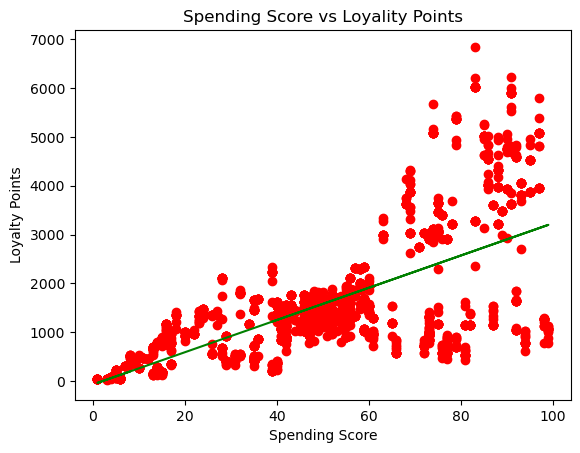

                spending_score  loyalty_points
spending_score         1.00000         0.67231
loyalty_points         0.67231         1.00000


In [12]:
# Plot the graph with a regression line.
plt.scatter(x_spend, y, color = "red")
plt.plot(x_spend, y_pred_spend, color = "green")

# Set the title and axis labels for the graph.
plt.title("Spending Score vs Loyality Points")
plt.xlabel("Spending Score")
plt.ylabel("Loyalty Points")

# Print the graph.
plt.show()

# Show the correlation between the dependent and independent variables.
corr_spend = reviews[["spending_score", "loyalty_points"]].corr()
print(corr_spend)

**Observation(s):** The correlation coefficient is 0.67 between the spending score and loyalty points variables. This indicates a moderately strong positive relationship, meaning that as a spending score increases, loyalty points tend to increase too. Therefore, Turtle Games could benefit from investigating the reason(s) for this relationship, e.g., a customer's spending score might directly influence how loyal they are, or their loyalty level might directly influence how much they spend (or both could be true).

### 5b) renumeration vs loyalty

In [13]:
# Define independent variable.
x_remuneration = reviews["remuneration"].values.reshape(-1, 1)

# Define dependent variable.
y = reviews["loyalty_points"].values.reshape(-1, 1)

# Create model and print summary of metrics.
slr_remuneration = linear_model.LinearRegression()
slr_remuneration.fit(x_remuneration, y)

# Print the R-squared value of the data.
print("R-squared value: ", slr_remuneration.score(x_remuneration, y))

# Print the intercept value.
print("Intercept value: ", slr_remuneration.intercept_)

# Print the coefficient value.
print("Coefficient value: ", slr_remuneration.coef_)

R-squared value:  0.3795357732793634
Intercept value:  [-65.6865128]
Coefficient value:  [[34.18782549]]


**Observation(s):** The R-squared is moderate and explains 37.95% of the dependent variable. The coefficient value tells us that each increase in remuneration by k£1 is associated with an increase in loyalty points by 34.19.

In [14]:
# Extract the estimated parameters, standard errors, and predicted values.

# Train the model using the 'statsmodel' OLS method.
# Fit the model with the added constant.
model_remuneration = sm.OLS(y, sm.add_constant(x_remuneration)).fit()

# Set the predicted response vector.
y_pred_remuneration = model_remuneration.predict(sm.add_constant(x_remuneration))

# Call a summary of the model.
print_model_remuneration = model_remuneration.summary()

# Print the summary.
print(print_model_remuneration)

# Print the predicted values.
print("Predicted values: ", y_pred_remuneration)

                            OLS Regression Results                            
Dep. Variable:                      y   R-squared:                       0.380
Model:                            OLS   Adj. R-squared:                  0.379
Method:                 Least Squares   F-statistic:                     1222.
Date:                Fri, 18 Sep 2026   Prob (F-statistic):          2.43e-209
Time:                        10:19:14   Log-Likelihood:                -16674.
No. Observations:                2000   AIC:                         3.335e+04
Df Residuals:                    1998   BIC:                         3.336e+04
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const        -65.6865     52.171     -1.259      0.2

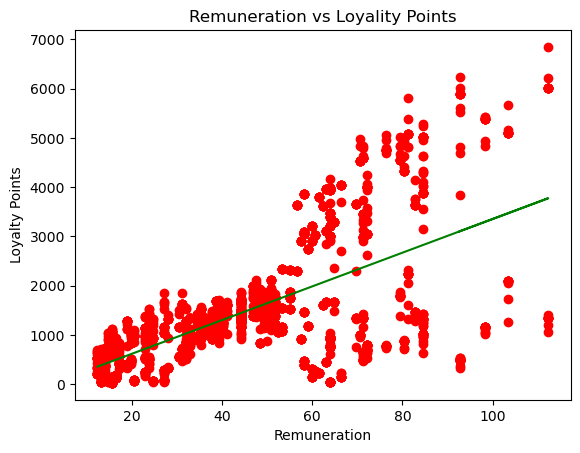

                remuneration  loyalty_points
remuneration        1.000000        0.616065
loyalty_points      0.616065        1.000000


In [15]:
# Plot the graph with a regression line.
plt.scatter(x_remuneration, y, color = "red")
plt.plot(x_remuneration, y_pred_remuneration, color = "green")

# Set the title and axis labels for the graph.
plt.title("Remuneration vs Loyality Points")
plt.xlabel("Remuneration")
plt.ylabel("Loyalty Points")

# Print the graph.
plt.show()

# Show the correlation between the dependent and independent variables.
corr_remuneration = reviews[["remuneration", "loyalty_points"]].corr()
print(corr_remuneration)

**Observation(s):** The correlation coefficient is 0.62 between the remuneration and loyalty points variables. This indicates a moderately strong positive relationship, meaning that as remuneration increases, loyalty points tend to increase too. Therefore, Turtle Games could benefit from investigating the reason(s) for this relationship, e.g., a customer's remuneration level might directly influence how loyal they are, or a customer's loyalty may not be at all related to their remuneration level, with their remuneration level naturally increasing over the period in which they have been a customer.

### 5c) age vs loyalty

In [16]:
# Define independent variable.
x_age = reviews["age"].values.reshape(-1, 1)

# Define dependent variable.
y = reviews["loyalty_points"].values.reshape(-1, 1)

# Create model and print summary of metrics.
slr_age = linear_model.LinearRegression()
slr_age.fit(x_age, y)

# Print the R-squared value of the data.
print("R-squared value: ", slr_age.score(x_age, y))

# Print the intercept value.
print("Intercept value: ", slr_age.intercept_)

# Print the coefficient value.
print("Coefficient value: ", slr_age.coef_)

R-squared value:  0.0018015480437203468
Intercept value:  [1736.5177394]
Coefficient value:  [[-4.01280515]]


**Observation(s):** The R-squared is weak and explains 0.0018% of the dependent variable. The coefficient value tells us that each increase in age by 1-year is associated with a decrease in loyalty points by 4.01.

In [17]:
# Extract the estimated parameters, standard errors, and predicted values.

# Train the model using the 'statsmodel' OLS method.
# Fit the model with the added constant.
model_age = sm.OLS(y, sm.add_constant(x_age)).fit()

# Set the predicted response vector.
y_pred_age = model_age.predict(sm.add_constant(x_age))

# Call a summary of the model.
print_model_age = model_age.summary()

# Print the summary.
print(print_model_age)

# Print the predicted values.
print("Predicted values: ", y_pred_age)

                            OLS Regression Results                            
Dep. Variable:                      y   R-squared:                       0.002
Model:                            OLS   Adj. R-squared:                  0.001
Method:                 Least Squares   F-statistic:                     3.606
Date:                Fri, 18 Sep 2026   Prob (F-statistic):             0.0577
Time:                        10:19:15   Log-Likelihood:                -17150.
No. Observations:                2000   AIC:                         3.430e+04
Df Residuals:                    1998   BIC:                         3.431e+04
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const       1736.5177     88.249     19.678      0.0

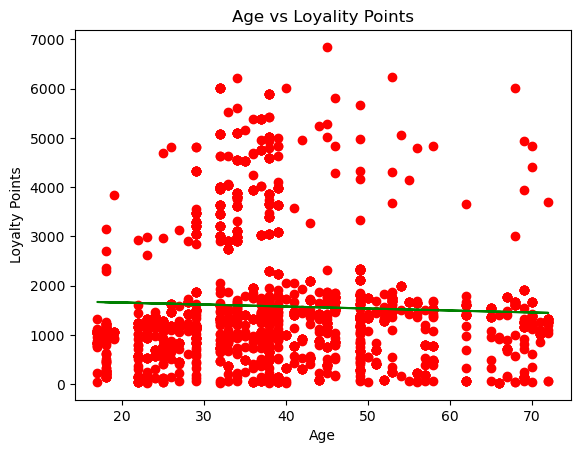

                     age  loyalty_points
age             1.000000       -0.042445
loyalty_points -0.042445        1.000000


In [18]:
# Plot the graph with a regression line.
plt.scatter(x_age, y, color = "red")
plt.plot(x_age, y_pred_age, color = "green")

# Set the title and axis labels for the graph.
plt.title("Age vs Loyality Points")
plt.xlabel("Age")
plt.ylabel("Loyalty Points")

# Print the graph.
plt.show()

# Show the correlation between the dependent and independent variables.
corr_age = reviews[["age", "loyalty_points"]].corr()
print(corr_age)

**Observation(s):** The correlation coefficient is -0.04 between the age and loyalty points variables. This indicates a weak negative relationship, meaning that as age increases, loyalty points might decrease by a negligible amount. This weak correlation suggests that age is not an important factor in influencing customer loyalty.

## 6. Observations and insights

***Your observations here...***






Of the three independent variables tested - spending score, remuneration, and age - spending score appears to be the best predictor of loyalty points, with an R-squared value of 45.20 and a correlation coefficient value of 0.67.

Remuneration is the next best predictor of loyalty points, with an R-squared value of 37.95 and a correlation coefficient value of 0.62.

However, remuneration has a greater coefficient value (34.19) than spending score does (33.06), indicating that increasing remuneration by k£1 has a slightly greater impact on loyalty points than increasing spending score by 1 does.

Regardless, both spending score and remuneration have moderately strong positive relationships with loyalty points, which, therefore, warrant further investigation into the direction(s) of causation.

Age is the worst predictor of loyalty points, with an R-squared value of 0.0018 and a correlation coefficient value of -0.04. This indicates a weak negative relationship, which suggests that age is not an important factor in influencing customer loyalty.

# Week 2 assignment: Exploring the structure using decision trees.

The team wants you to use decision trees to attempt to better understand the structure found in the data. You need to grow and prune a decision tree regressor and then visualise and interpret the output.
Make sure to comment on the potential usefulness in decision-making processes and your observations regarding the model.

## Instructions
1. Prepare the data for creating your decision tree. 
    1. Import the CSV file you have prepared in Week 1.
    2. Create a new DataFrame with the appropriate columns.
        1. Specify that loyalty points is the target variable (Y) and should be excluded from your input data.
        2. Specify X for the independent variables and y as the dependent variable. Therefore, df\[cols\] will be the independent variables and the column containing loyalty points the dependent variable.
        3. Explore the new DataFrame. 
2. Split the data set into a train and test sets for both X and y at a 70:30 ratio. As previously, random_state=42.
3. Create a decision tree regressor to explore the impact of other features on the loyalty points.
    1. Import the DecisionTreeRegressor class from the sklearn.tree library. 
    2. Create a variable (e.g. regressor) to store the DecisionTreeRegressor() class. (As previously, random_state=42.).
    3. Fit the regressor object to the data set with the fit() function.
    4. Remember to prune your tree using basic pruning strategies and compare the performance before and after applying the pruning strategy.
    5. Plot the final decision tree.
4. Fit a final model and interpret the output.
    1. Justify your selection of pruning strategy implemented and interpret the output.
    2. Evaluate the usefulness of the obtained result and interpret the tree and how it could be used to inform business decisions in the organisation.
5. Summarise (150–200 words) the most important business insights, anything you would like to explore further, and suggested future actions.
 
Back up your work to a safe location. This will allow you to revert to a previous state in the case of making a mistake in the code or deleting a section by mistake. (A simple way of doing this is to save or email a compressed version to yourself at frequent intervals.)


## 1. Load and prepare the data

In [19]:
# Imports:
# Data analysis:
import pandas as pd
import numpy as np

# Linear regression:
import statsmodels.api as sm
from sklearn import tree
from sklearn.tree import DecisionTreeRegressor, plot_tree 
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay
import math

# Warnings.
import warnings

# Settings for the notebook.
warnings.filterwarnings("ignore")
plt.rcParams["figure.figsize"] = [15, 10]

In [20]:
# Create your new DataFrame.
df2 = reviews_nec_col

In [21]:
# Specify y.
y = df2["loyalty_points"]

# Specify X.
X = df2.drop("loyalty_points", axis = 1)

In [22]:
# Review X and y.
print(y)
X

0        210
1        524
2         40
3        562
4        366
        ... 
1995    4031
1996     539
1997    5614
1998    1048
1999     479
Name: loyalty_points, Length: 2000, dtype: int64


,gender,age,remuneration,spending_score,education,product,review,summary
0,Male,18,12.30,39,graduate,453,"When it comes to a DM's screen, the space on t...",The fact that 50% of this space is wasted on a...
1,Male,23,12.30,81,graduate,466,An Open Letter to GaleForce9*:\n\nYour unpaint...,Another worthless Dungeon Master's screen from...
2,Female,22,13.12,6,graduate,254,"Nice art, nice printing. Why two panels are f...","pretty, but also pretty useless"
3,Female,25,13.12,77,graduate,263,Amazing buy! Bought it as a gift for our new d...,Five Stars
4,Female,33,13.94,40,graduate,291,As my review of GF9's previous screens these w...,Money trap
...,...,...,...,...,...,...,...,...
1995,Female,37,84.46,69,PhD,977,The perfect word game for mixed ages (with Mom...,The perfect word game for mixed ages (with Mom
1996,Female,43,92.66,8,PhD,979,Great game. Did not think I would like it whe...,Super fun
1997,Male,34,92.66,91,graduate,1012,Great game for all.........\nKeeps the mind ni...,Great Game
1998,Male,34,98.40,16,PhD,1031,fun game!,Four Stars


**Observation(s):** The review and summary columns contain free-text data. Whilst this may be valuable, qualitative data for the business to consider, the inclusion of it in the decision tree model will cause issues with interpretability. Therefore, they will be dropped from the DataFrame for the purposes of this exercise.

In [23]:
# Drop the review and summary columns.
X = df2.drop(["review", "summary"], axis=1)

# View column names.
print(X.columns)

Index(['gender', 'age', 'remuneration', 'spending_score', 'loyalty_points',
       'education', 'product'],
      dtype='object')


In [24]:
# View the data types.
print(X.dtypes)

gender             object
age                 int64
remuneration      float64
spending_score      int64
loyalty_points      int64
education          object
product             int64
dtype: object


In [25]:
# Name new DataFrame and convert categorical variables to dummy variables.
cat_vars=["gender", "education"]

# Use the for loop keyword to specify what actions to apply to all the 'var' items.
for var in cat_vars:
    # Specify details of the categorical list.
    cat_list = pd.get_dummies(X[var], prefix = var)
    # Drop the first column.
    cat_list = cat_list.iloc[:, 1:]
    # Indicate the joining of the DataFrames.
    X = X.join(cat_list)

X_fin = X.drop(cat_vars, axis = 1)

# Set a temporary DataFrame and add values.
X_vars = X.columns.values.tolist()

# Indicate what columns are kept.
to_keep = [i for i in X_vars if i not in cat_vars]

# Define new DataFrame.
X_fin = X[to_keep]

# Print the column.
X_fin.columns.values

array(['age', 'remuneration', 'spending_score', 'loyalty_points',
       'product', 'gender_Male', 'education_PhD', 'education_diploma',
       'education_graduate', 'education_postgraduate'], dtype=object)

In [26]:
# Redefine X using the encoded data.
X = X_fin.drop("loyalty_points", axis = 1)  # X now has encoded variables.
y = X_fin["loyalty_points"]               # y stays the same.

## 2. Create train and test data sets

In [27]:
# Split the data into test and train data.
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.3, random_state = 42)

## 3. Create Decision tree regressor

In [28]:
# Create your decision tree regressor.
regression = DecisionTreeRegressor(random_state = 42)

# Train the decision tree regressor.
regression = regression.fit(X_train, y_train)

In [29]:
# Evaluate the model.
# Predict the response for the data test.
y_pred = regression.predict(X_test)

# Specify to print the Mean Absolute Error (MAE) and Mean Squared Error (MSE) to evaluate the accuracy of the model.
print("Mean Absolute Error: ", metrics.mean_absolute_error(y_test, y_pred))
print("Mean Squared Error: ", metrics.mean_squared_error(y_test, y_pred))
# Calculate the Root Mean Squared Error (RMSE).
print("Root Mean Squared Error: ", math.sqrt(metrics.mean_squared_error(y_test, y_pred)))

Mean Absolute Error:  39.248333333333335
Mean Squared Error:  10197.558333333332
Root Mean Squared Error:  100.98296060887368


**Observation(s):** The output indicates that the MAE is 39.25, the MSE is 10,197.56, and the RMSE is 100.98 (here, rounded to two decimals).

An MAE of 39.25 means that, on average, the model's predictions are off by about 39 units from the actual values. MAE ignores whether predictions are too high or too low.

An MSE of 10,197.56 indicates the average of squared errors. Because errors are squared, MSE penalises larger errors more heavily than smaller errors, making it useful when you want to catch and minimise big prediction mistakes.

An RMSE of 100.98 means that, on average, the model's predictions are off by about 101 units from the actual values. RMSE also penalises larger errors more heavily than smaller errors, making it it useful when you want to catch and minimise big prediction mistakes. However, RMSE also returns the error to the same units as your target variable (making it easier to interpret).

The RMSE is notably larger than the MAE, suggesting that the model has some larger errors alongside more typical, smaller ones.

Numbers closer to 0 indicate better performance, but whether your specific values represent good model performance depends on:

- **The scale of your target variable** - Are values in the hundreds or thousands? An MAE of 39.25 and an RMSE of 100.98 might be poor or excellent depending on this.

- **Your business context** - What level of prediction error is acceptable for your use case?

**Absolute accuracy:** The maximum value of the target variable (loyalty points) is 6,847. This means that the MAE and RMSE are relatively good in this business context, as errors of between 39 and 101 units represent roughly **0.57% - 1.48%** error margins. The MAE and RMSE would be much worse if the maximum value of the target variable was in the hundreds, e.g., 685, as this would mean the errors margins would be between roughly 5.69% and 14.74%.

**Error consistency:** The difference between the RMSE (100.98) and the MAE (39.25) is 61.73. As a percentage of the maximum value of the target variable (6,847), 61.73 represents **0.90%**. This suggests that the model's errors are largely consistent, meaning it doesn't tend to have extremely large errors mixed in with the small ones. However, as the model's prediction error is not 0, the model's errors will vary in size, meaning it will occasionally make much larger prediction mistakes.

In [30]:
# Prune the model.
regression_p = DecisionTreeRegressor(criterion = "squared_error",
                             max_depth = 5,
                             min_samples_leaf = 5,
                             min_samples_split = 5,
                             random_state = 42)
regression_p.fit(X_train, y_train)
y_pred_p = regression_p.predict(X_test)

# Specify to print the Mean Absolute Error (MAE) and Mean Squared Error (MSE) to evaluate the accuracy of the new model.
print("Mean Absolute Error: ", metrics.mean_absolute_error(y_test, y_pred_p))
print("Mean Squared Error: ", metrics.mean_squared_error(y_test, y_pred_p))
# Calculate the Root Mean Squared Error (RMSE).
print("Root Mean Squared Error: ", math.sqrt(metrics.mean_squared_error(y_test, y_pred_p)))

Mean Absolute Error:  177.2664367154586
Mean Squared Error:  70229.10691738166
Root Mean Squared Error:  265.0077487874301


**Observation(s):** The output indicates that the MAE is 177.27, the MSE is 70,229.11, and the RMSE is 265.01 (here, rounded to two decimals).

These results indicate that the pruned model performs worse than the unpruned model. This is because the pruning parameters (max_depth = 5, min_samples_leaf = 5, min_samples_split = 5) have simplified the model to the point that it can no longer capture important patterns in the data (underfitting).

For the purposes of this excercise, the decision has been taken to use the unpruned model instead. However, it should be noted that experimentation with different pruning parameters could lead to a better-performing pruned model (which could potentially perform better than the unpruned model).

## 4. Fit and plot final model

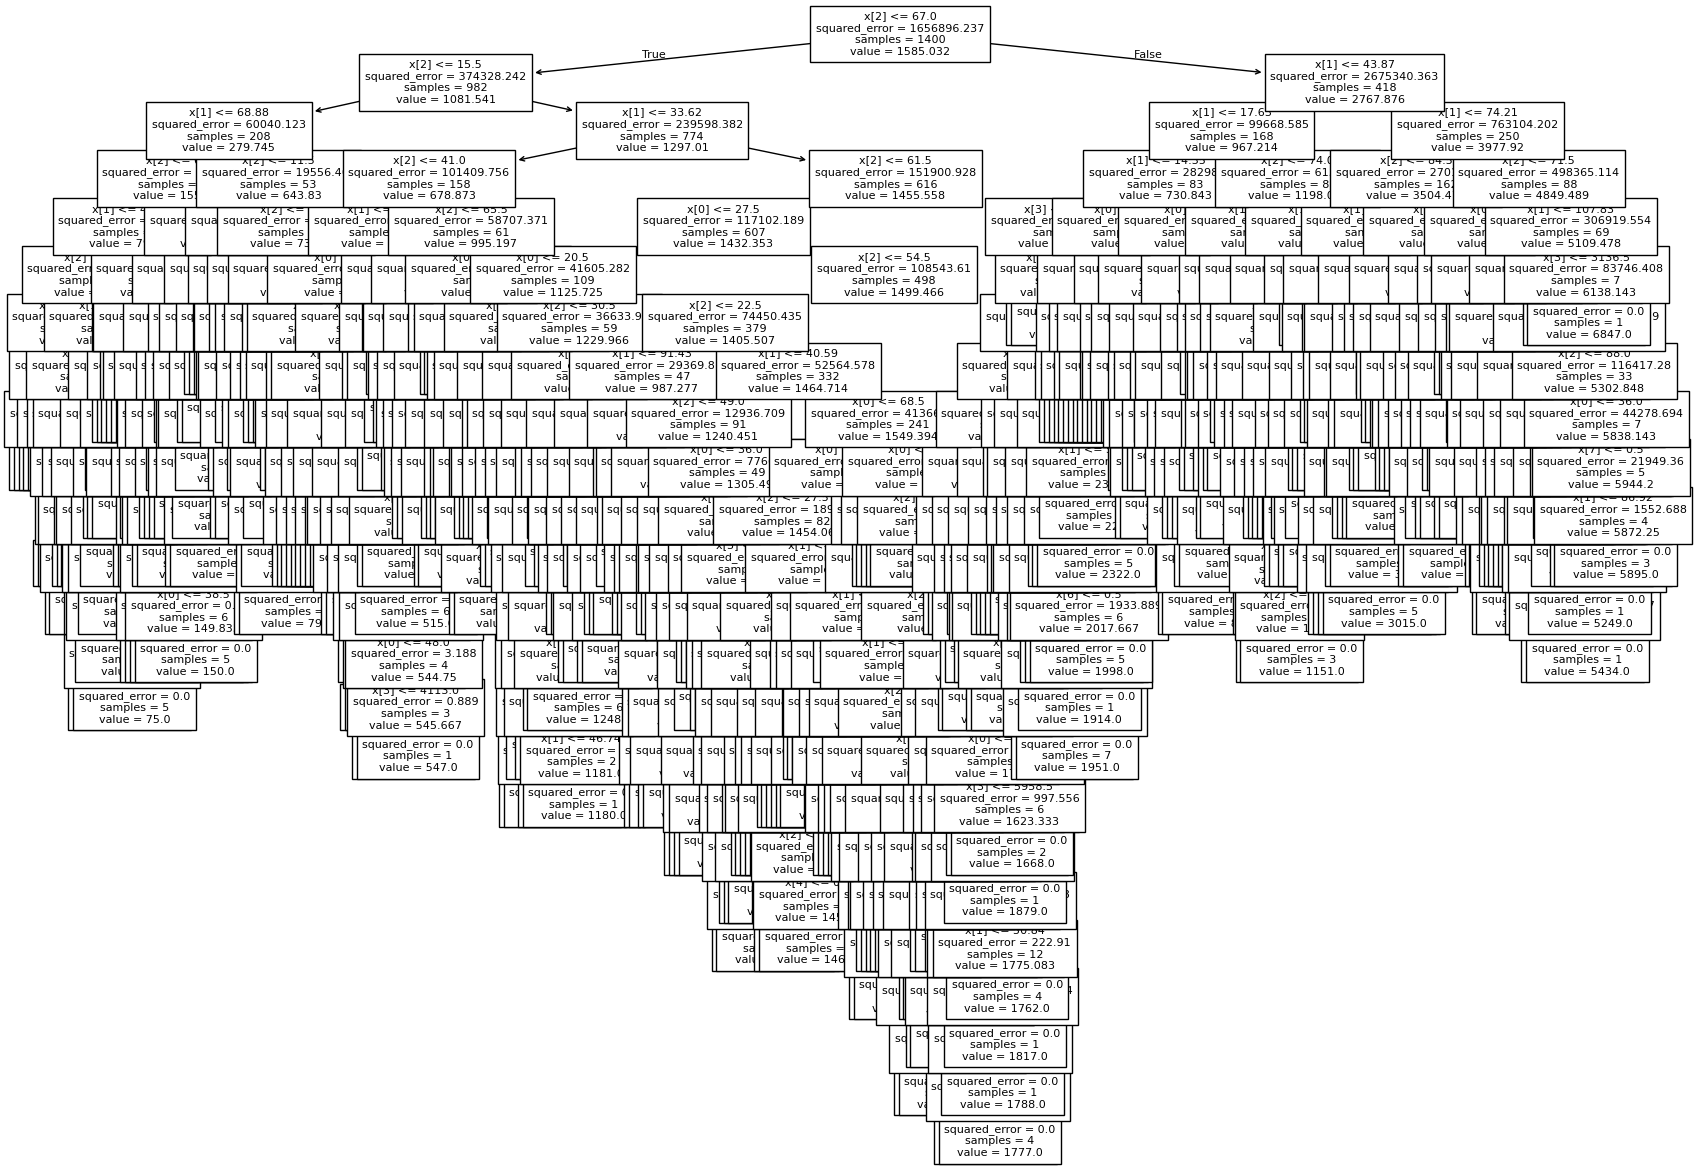

In [31]:
# Fit and plot final model.
fig, ax = plt.subplots(figsize = (20, 15))
tree.plot_tree(regression, fontsize = 8, ax = ax)

# Print the plot with plt.show().
plt.show()

**Observation(s):** The decision tree visualisation is too large and too complex to be able to meaningfully interpret the results, due to the number of features and their interactions. Therefore, feature importance analysis will be undertaken to better understand which variables contribute most to predicting the target variable (loyalty points).

                  Feature  Importance
1            remuneration    0.497246
2          spending_score    0.483997
0                     age    0.016846
3                 product    0.000844
5           education_PhD    0.000324
6       education_diploma    0.000237
4             gender_Male    0.000226
7      education_graduate    0.000202
8  education_postgraduate    0.000078


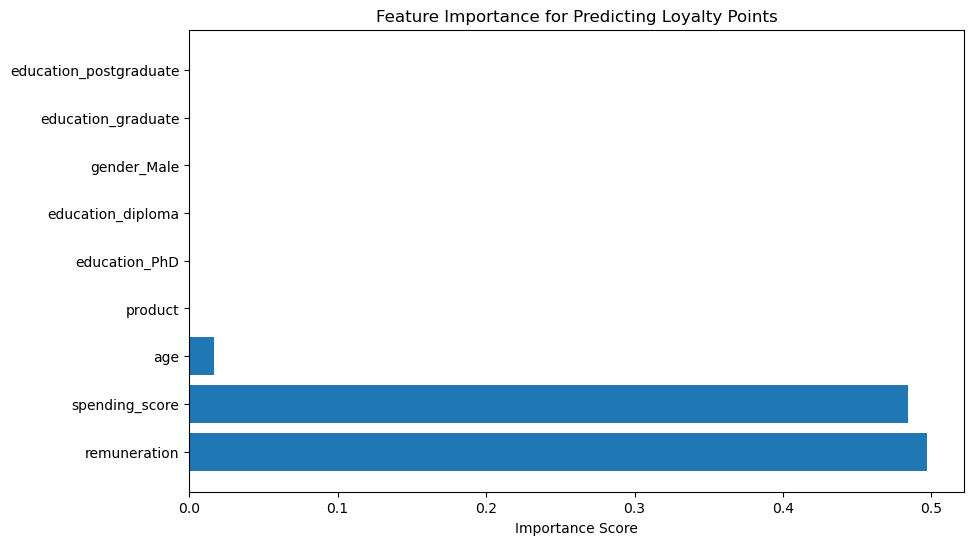

In [32]:
# Undertake importance analysis on features.
importance = regression.feature_importances_

# Create a DataFrame to see which features are the most important.
feature_importance = pd.DataFrame({
    "Feature": X.columns,
    "Importance": importance
}).sort_values("Importance", ascending=False)

# View the DataFrame.
print(feature_importance)

# Plot feature importance.
plt.figure(figsize = (10, 6))
plt.barh(feature_importance["Feature"], feature_importance["Importance"])
plt.xlabel('Importance Score')
plt.title('Feature Importance for Predicting Loyalty Points')
plt.show()

**Observation(s):** The feature importance analysis informs us that remuneration (49.72%) and spending score (48.40%) account for approximately 98.12% of the model's decision-making, with age accounting for another 1.68%, and all the other features accounting for the remaining 0.20%. Therefore, the only "important" features are remuneration and spending score (both financial characteristics), whilst features that represent demographic characteristics barely matter at all.

However, correlation doesn't prove causation, so we cannot determine whether remuneration, spending, or both drive loyalty points, or if, conversely, loyalty points drive remuneration, spending, or both (although common sense dictates that loyalty points would not drive remuneration)."

Therefore, Turtle Games could consider launching a customer loyalty programme that relates to financial characteristics, e.g., 'spend-based rewards', as this would align with observed customer behaviour much better than, for example, a programme which is targeted at customers of a particular gender or education level (which, as well as being ineffective, would also likely be discriminatory).

## 5. Discuss: Insights and observations

***Your observations here...***

Of the two decision tree models, the unpruned model performs better at predicting loyalty points, because the pruned model has been underfitted. Therefore, the unpruned model was used instead.

The unpruned model has an MAE of 39.25, an MSE of 10,197.56, and an RMSE of 100.98. The RMSE is notably larger than the MAE, suggesting that the model has some larger errors alongside more typical, smaller ones. The error margins are 0.57% - 1.48% and the error consistency is 0.90%, suggesting that the model's errors are largely consistent.

The decision tree visualisation is too large and complex for us to interpret the results, due to the number of features and their interactions. Therefore, feature importance analysis was undertaken to better understand which variables contribute most to predicting loyalty points. This analysis informs us that remuneration (49.72%) and spending score (48.40%) account for approximately 98.12% of the model's decision-making. 

Therefore, Turtle Games could consider launching a loyalty programme that relates to financial characteristics, e.g., 'spend-based rewards', which would align with observed customer behaviour much better than a programme which is targeted at customers of a particular gender or education level (which, as well as being ineffective, would also likely be discriminatory).

# Week 3 assignment: Clustering with *k*-means using Python

The marketing department also wants to better understand the usefulness of renumeration and spending scores but do not know where to begin. You are tasked to identify groups within the customer base that can be used to target specific market segments. Use *k*-means clustering to identify the optimal number of clusters and then apply and plot the data using the created segments.

## Instructions
1. Prepare the data for clustering. 
    1. Import the CSV file you have prepared in Week 1.
    2. Create a new DataFrame (e.g. `df3`) containing the `renumeration` and `spending_score` columns.
    3. Explore the new DataFrame. 
2. Plot the renumeration versus spending score.
    1. Create a scatterplot.
    2. Create a pairplot.
3. Use the Silhouette and Elbow methods to determine the optimal number of clusters for *k*-means clustering.
    1. Plot both methods and explain how you determine the number of clusters to use.
    2. Add titles and legends to the plot.
4. Evaluate the usefulness of at least three values for *k* based on insights from the Elbow and Silhoutte methods.
    1. Plot the predicted *k*-means.
    2. Explain which value might give you the best clustering.
5. Fit a final model using your selected value for *k*.
    1. Justify your selection and comment on the respective cluster sizes of your final solution.
    2. Check the number of observations per predicted class.
6. Plot the clusters and interpret the model.

## 1. Load and explore the data

In [33]:
# Import necessary libraries.
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.cm as cm
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.metrics import accuracy_score
from scipy.spatial.distance import cdist

import warnings
warnings.filterwarnings("ignore")

In [34]:
# Load the CSV file(s) as df3.
df3 = reviews_nec_col

# View DataFrame.
df3.head()

,gender,age,remuneration,spending_score,loyalty_points,education,product,review,summary
0,Male,18,12.30,39,210,graduate,453,"When it comes to a DM's screen, the space on t...",The fact that 50% of this space is wasted on a...
1,Male,23,12.30,81,524,graduate,466,An Open Letter to GaleForce9*:\n\nYour unpaint...,Another worthless Dungeon Master's screen from...
2,Female,22,13.12,6,40,graduate,254,"Nice art, nice printing. Why two panels are f...","pretty, but also pretty useless"
3,Female,25,13.12,77,562,graduate,263,Amazing buy! Bought it as a gift for our new d...,Five Stars
4,Female,33,13.94,40,366,graduate,291,As my review of GF9's previous screens these w...,Money trap


In [35]:
# Drop unnecessary columns.
df3 = df3.drop(["gender", "age", "loyalty_points", "education", "product", "review", "summary"], axis=1)

# View DataFrame.
df3.head()

,remuneration,spending_score
0,12.30,39
1,12.30,81
2,13.12,6
3,13.12,77
4,13.94,40


In [36]:
# Explore the data.

# Check for null values.
df3.isnull().sum()

remuneration      0
spending_score    0
dtype: int64

**Observation(s):** There are no null values in the remuneration or spending_score columns, as was determined in week 1.

In [37]:
# Descriptive statistics.
df3.describe()

,remuneration,spending_score
count,2000.000000,2000.000000
mean,48.079060,50.000000
std,23.123984,26.094702
min,12.300000,1.000000
25%,30.340000,32.000000
50%,47.150000,50.000000
75%,63.960000,73.000000
max,112.340000,99.000000


**Observation(s):** The mean value of each column is higher than their STD, which indicates low variability of values within the two columns. However, there is a (relatively) large gap between the first and third quartiles and between the third quartile and max value in both columns, indicating that outliers are likely to exist in them.

## 2. Plot

<Axes: xlabel='remuneration', ylabel='spending_score'>

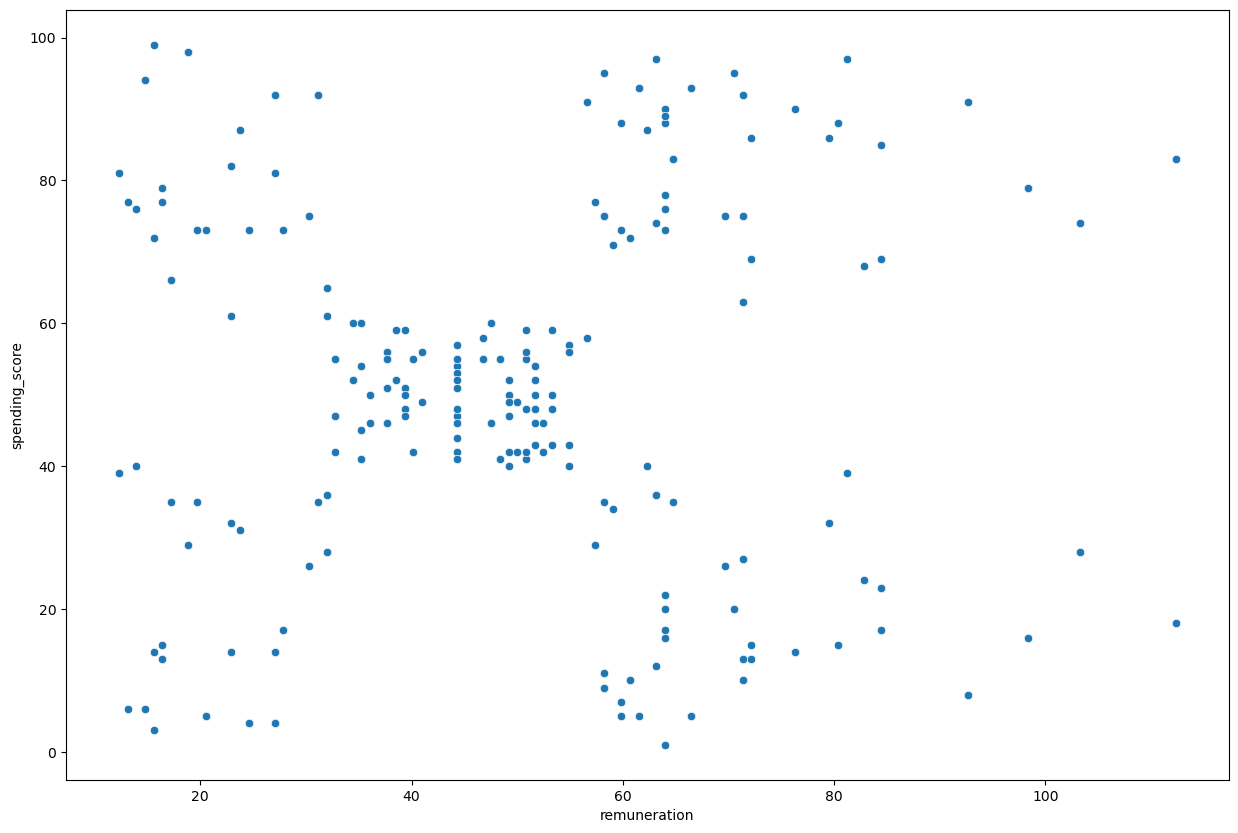

In [38]:
# Create a scatterplot with Seaborn.
sns.scatterplot(x = "remuneration",
                y = "spending_score",
                data = df3)

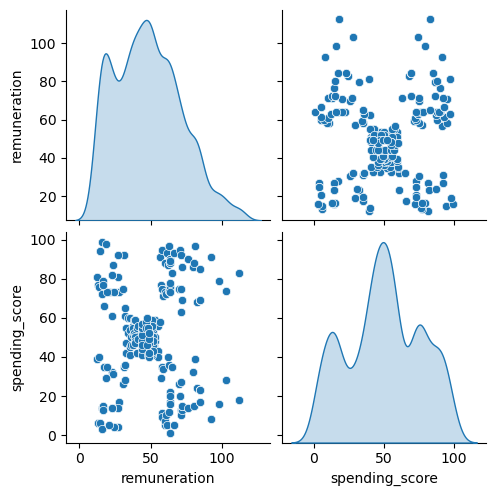

In [39]:
# Create a pairplot with Seaborn.
x = df3[["remuneration", "spending_score"]]

sns.pairplot(df3,
             vars = x,
             diag_kind = "kde")

## 3. Elbow and silhoutte methods

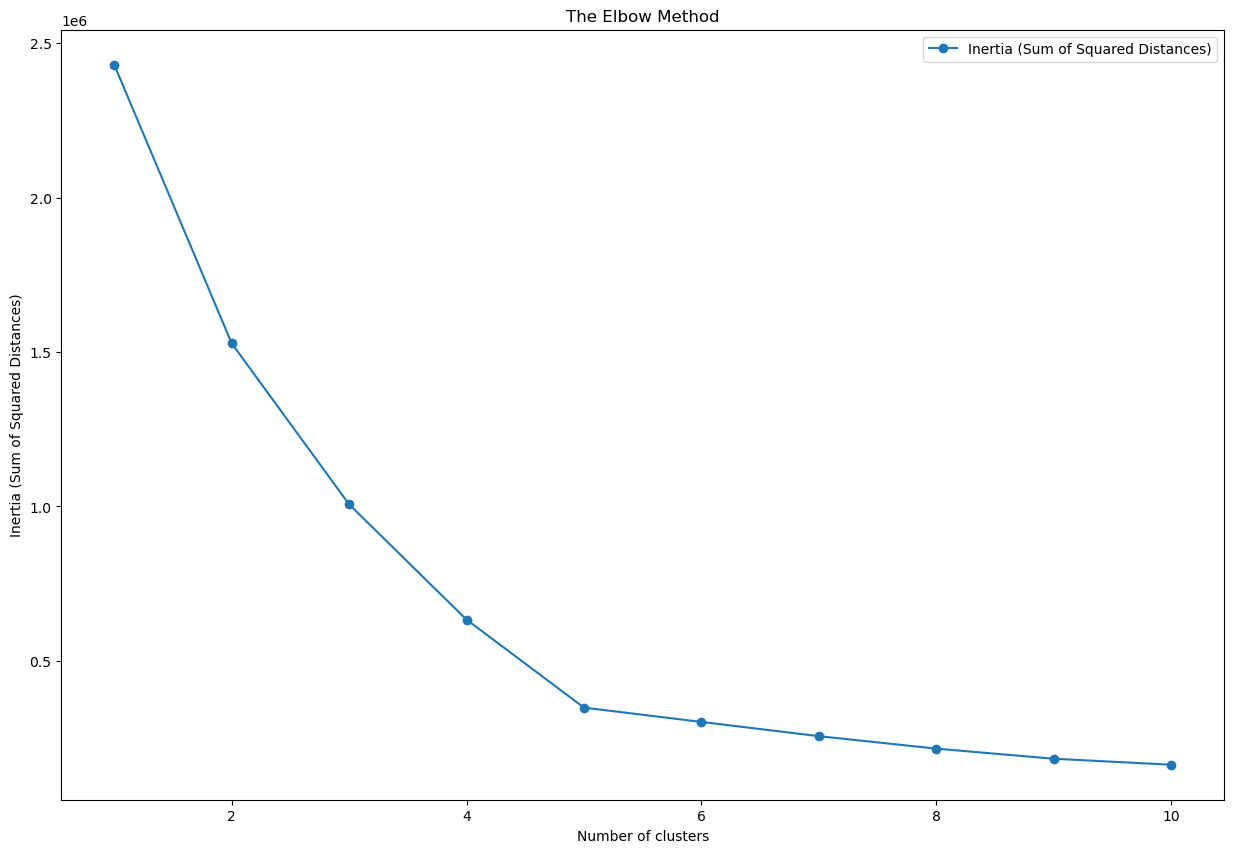

In [40]:
# Determine the number of clusters: Elbow method.
ss = []
for i in range(1, 11):
    kmeans = KMeans(n_clusters=i,
                    init="k-means++",
                    max_iter=500,
                    n_init=10,
                    random_state=42)
    kmeans.fit(x)
    ss.append(kmeans.inertia_)

# Plot the elbow method.
plt.plot(range(1, 11),
         ss,
         marker="o")

# Insert labels and title.
plt.title("The Elbow Method")
plt.xlabel("Number of clusters")
plt.ylabel("Inertia (Sum of Squared Distances)")
plt.legend(["Inertia (Sum of Squared Distances)"])

plt.show()

**Observation(s):** There is a consistent downward trajectory between one and ten clusters, with the curve beginning to flatten after four clusters and having mostly flattened after six clusters.

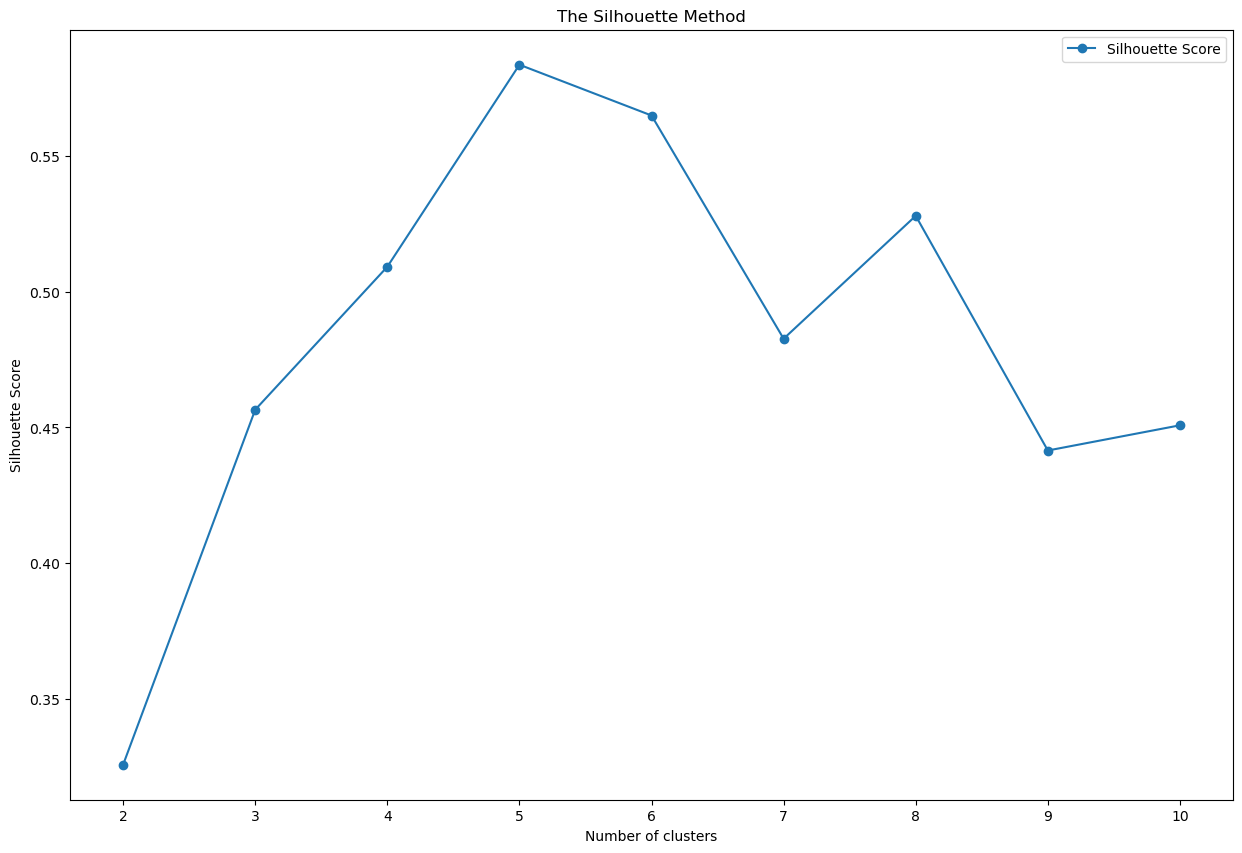

In [41]:
# Determine the number of clusters: Silhouette method.
sil = []
kmax = 10

for k in range(2, kmax+1):
    kmeans_s = KMeans(n_clusters=k).fit(x)
    labels = kmeans_s.labels_
    sil.append(silhouette_score(x,
                                labels,
                                metric="euclidean"))

# Plot the silhouette method.
plt.plot(range(2, kmax+1),
         sil,
         marker="o")

# Insert labels and title.
plt.title("The Silhouette Method")
plt.xlabel("Number of clusters")
plt.ylabel("Silhouette Score")
plt.legend(["Silhouette Score"])

plt.show()

**Observation(s):** There is a consistent upward trajectory between one and four clusters, followed by a slight decrease between four and five clusters, a sharp increase between five and six clusters, and then a sharp decrease between six and seven clusters (to below cluster five).

Therefore, four, five, and six clusters will be tested.

## 4. Evaluate k-means model at different values of *k*

### a. Four clusters

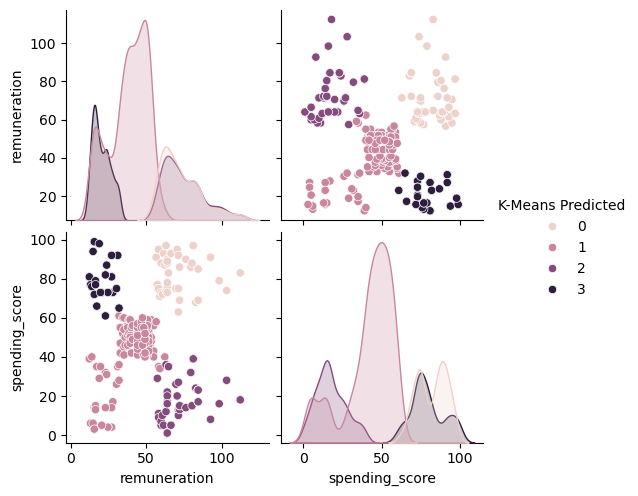

In [42]:
# Use four clusters.
kmeans = KMeans(n_clusters = 4,
                max_iter = 15000,
                init = "k-means++",
                random_state = 42).fit(x)

clusters = kmeans.labels_

x["K-Means Predicted"] = clusters

# Plot the predicted.
sns.pairplot(x,
             hue="K-Means Predicted",
             diag_kind= "kde")

In [43]:
# Check the number of observations per predicted class.
x["K-Means Predicted"].value_counts()

K-Means Predicted
1    1045
0     356
2     330
3     269
Name: count, dtype: int64

In [44]:
# View the K-Means predicted.
print(x.head())

   remuneration  spending_score  K-Means Predicted
0         12.30              39                  1
1         12.30              81                  3
2         13.12               6                  1
3         13.12              77                  3
4         13.94              40                  1


**Observation(s):** Cluster 1 has far more observations (1,045) than clusters 0, 2, and 3 do (356, 330, and 239 respectively).

This imbalance could be problematic for Turtle Games, because customers in cluster 1 may not have been segmented enough for us to be able to draw any meaningful insights about them, and could mean that targeted marketing efforts would not be successful with many customers in the cluster (because they may not relate that well to the marketing or to the other customers being targeted).

However, this imbalance may not be too much of an issue, as clusters 0, 2, and 3 also have significant numbers of customers within them (in real terms), meaning that they represent distinct customer segments that can be targeted, with cluster 1 potentially being a "mainstream" segment (although the value of targeting this particular mainstream segment could be low, given it mostly represents those customers with both the lowest/ mid-lowest levels of remuneration and spending_scores).

Five- and six-cluster models must now be developed for comparison with the four-cluster model.

### b. Five clusters

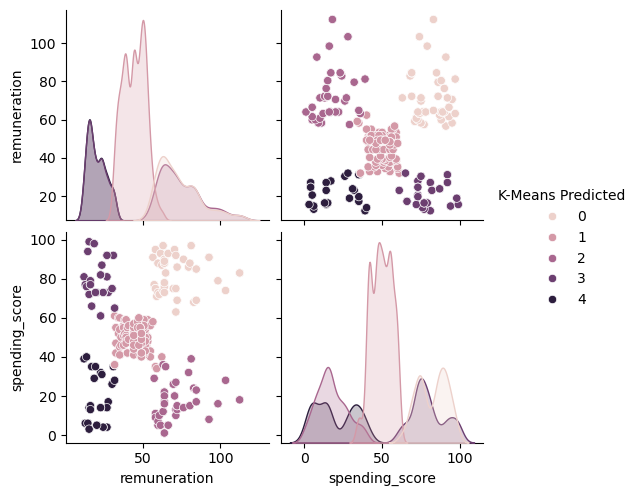

In [45]:
# Use five clusters.
kmeans = KMeans(n_clusters = 5,
                max_iter = 15000,
                init = "k-means++",
                random_state = 42).fit(x)

clusters = kmeans.labels_

x["K-Means Predicted"] = clusters

# Plot the predicted.
sns.pairplot(x,
             hue="K-Means Predicted",
             diag_kind= "kde")

In [46]:
# Check the number of observations per predicted class.
x["K-Means Predicted"].value_counts()

K-Means Predicted
1    774
0    356
2    330
4    271
3    269
Name: count, dtype: int64

In [47]:
# View the K-Means predicted.
print(x.head())

   remuneration  spending_score  K-Means Predicted
0         12.30              39                  4
1         12.30              81                  3
2         13.12               6                  4
3         13.12              77                  3
4         13.94              40                  4


**Observation(s):** The five-cluster model is much more balanced than the four-cluster model. However, cluster 1 still has far more observations (774) than clusters 0, 2, 4, and 3 do (356, 330, 271, and 269 respectively). Clusters 0 and 2 have remained the same, whilst some of the customers from cluster 1 have moved to the new cluster 4 and the pre-existing cluster 3.

This imbalance could still be problematic for Turtle Games (because of the risk of marketing ineffectiveness for cluster 1) or may not be an issue (because the other four clusters represent distinct customer segments). However, the five-cluster model appears to be better than the four-cluster model, because it is more balanced, all five clusters represent distinct customer segments, and there is now a clear distinction between those customers that have both the lowest levels of remuneration and spending scores from those customers with mid-level remuneration and spending scores.

A six-cluster model must now be developed for comparison with the four- and five-cluster models.

### c. Six clusters

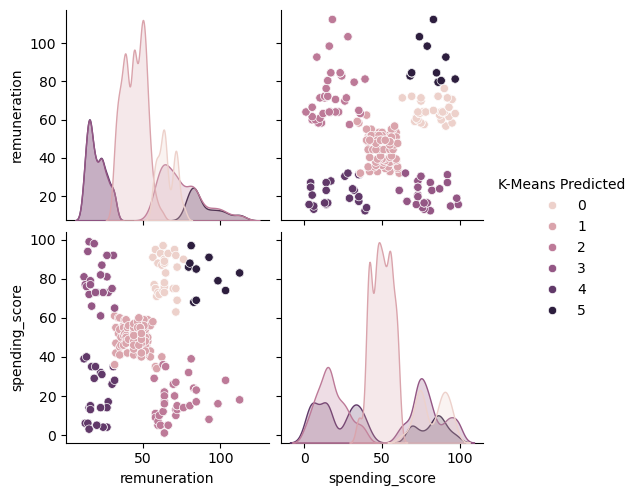

In [48]:
# Use six clusters.
kmeans = KMeans(n_clusters = 6,
                max_iter = 15000,
                init = "k-means++",
                random_state = 42).fit(x)

clusters = kmeans.labels_

x["K-Means Predicted"] = clusters

# Plot the predicted.
sns.pairplot(x,
             hue="K-Means Predicted",
             diag_kind= "kde")

In [49]:
# Check the number of observations per predicted class.
x["K-Means Predicted"].value_counts()

K-Means Predicted
1    774
2    330
4    271
3    269
0    238
5    118
Name: count, dtype: int64

In [50]:
# View the K-Means predicted.
print(x.head())

   remuneration  spending_score  K-Means Predicted
0         12.30              39                  4
1         12.30              81                  3
2         13.12               6                  4
3         13.12              77                  3
4         13.94              40                  4


**Observation(s):** The six-cluster model is much more balanced than the four-cluster model but slightly less balanced than the five-cluster model. Cluster 1 still has far more observations (774) than clusters 2, 4, 3, 0, and 5 do (330, 271, 269, 238, 118 respectively). Clusters 1, 2, 4, and 3 have remained the same, whilst some of the customers from cluster 0 have moved to the new cluster 5.

This imbalance could still be problematic for Turtle Games (because of the risk of marketing ineffectiveness for cluster 1) or may not be an issue (because the other five clusters represent distinct customer segments). However, the six-cluster model appears to be better than the four-cluster model and slightly worse than the five-cluster model. This is because it is more balanced than the four-cluster model and slightly less balanced than the five-cluster model, all six clusters represent distinct customer segments, and the customers with both the highest levels of remuneration and spending scores have been split between clusters 0 (mid-high levels) and 5 (highest levels).

This split could be advantageous to Turtle Games if, for example, they wanted to target their most premium offers at customers in cluster 5. However, cluster 5 is much smaller than the other clusters, meaning it could be just as effective to maintain these "high-earning / high-spending" customers within cluster 0 and target all the customers with the same marketing.

## 5. Fit final model and justify your choice

**Justification for model choice:** On balance, the recommendation is to use the five-cluster model, as this provides balance, distinct customer segments to understand and target, and large enough customer segments to warrant tailored marketing efforts for each.

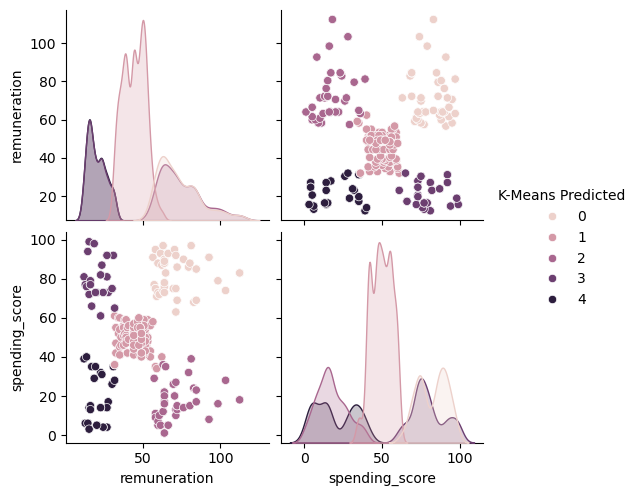

In [51]:
# Apply the final model.
kmeans = KMeans(n_clusters = 5,
                max_iter = 15000,
                init = "k-means++",
                random_state = 42).fit(x)

clusters = kmeans.labels_

x["K-Means Predicted"] = clusters

# Plot the predicted.
sns.pairplot(x,
             hue="K-Means Predicted",
             diag_kind= "kde")

In [52]:
# Check the number of observations per predicted class.
x["K-Means Predicted"].value_counts()

K-Means Predicted
1    774
0    356
2    330
4    271
3    269
Name: count, dtype: int64

In [53]:
# View the K-Means predicted.
print(x.head())

   remuneration  spending_score  K-Means Predicted
0         12.30              39                  4
1         12.30              81                  3
2         13.12               6                  4
3         13.12              77                  3
4         13.94              40                  4


## 6. Plot and interpret the clusters

<Axes: xlabel='remuneration', ylabel='spending_score'>

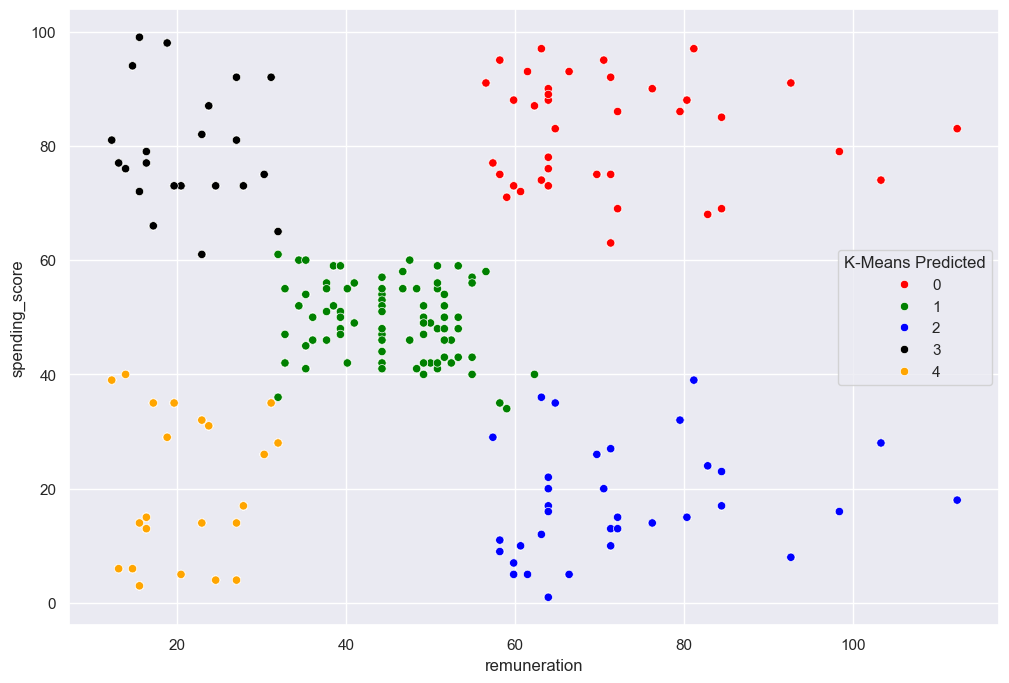

In [54]:
# Visualising the clusters.
# Set plot size.
sns.set(rc = {"figure.figsize":(12, 8)})

# Create a scatterplot.
sns.scatterplot(x = "remuneration" ,
                y = "spending_score",
                data = x,
                hue = "K-Means Predicted",
                palette = ["red", "green", "blue", "black", "orange"])

**Observation(s):** The largest cluster is no. 1, representing 774 customers who earn approximately £30k-£60k and who have spending scores between approximately 40 and 60. This is likely to be an important cluster to Turtle Games because it represents the greatest number of customers and also mid-level remuneration and spending scores.

Cluster 0 is the next largest, representing 356 customers who earn approximately £60k-£100k+ and who have spending scores between approximately 0 and 40. This is also likely to be an important cluster because it represents a fairly large number of high-income customers who could potentially be encouraged to spend more.

Cluster 2 is the next largest, representing 330 customers who earn approximately £60k-£100k+ and who have spending scores between approximately 60 and 100. This is likely to be a cluster of mid-level important because it represents a fairly large number of high-income customers, many of whom are already spending a lot, but some of whom could potentially be encouraged to spend more.

Clusters 4 and 3 are the smallest, representing 271 and 269 customers respectively, who earn approximately £10k-£30k. Cluster 4 represents those customers with spending scores of between approximately 0 and 40, whilst cluster 3 represents those customers with spending scores of between approximately 60 and 100. Niether of these clusters are likely to be of great importance, as cluster 4 represents low-income customers who are spending little (probably because they cannot afford to spend more), whilst cluster 3 represents low-income customers who are spending a lot (and who also probably cannot afford to spend more).

Therefore, Turtle Games may benefit from targeting those customers in clusters 0, 1, and 2, as they represent mid- to high-level income and varying levels of spending, most of whom could potentially be encouraged to spend more.

## 7. Discuss: Insights and observations

***Your observations here...***

The five-cluster model has been chosen because it is the most balanced, provides distinct customer segments to understand and target, and the segments are large enough to warrant tailored marketing efforts for each.

However, the five-cluster model is slightly imbalanced, which could be problematic, because customers in cluster 1 may not have been segmented enough for targeted marketing efforts to be successful. Therefore, additional investigation into this cluster’s heterogeneity could reveal sub-segments within that are worth targeting differently.

The imbalance may not be too much of an issue though, as the other clusters also represent distinct segments that are large enough to warrant targeting.

Cluster 1 is the largest, representing 774 customers who earn approximately £30k-£60k, with spending scores between approximately 40 and 60. Cluster 0 is the second largest, representing 356 customers who earn approximately £60k-£100k+, with spending scores between approximately 0 and 40. Cluster 2 is the third largest, representing 330 customers who earn approximately £60k-£100k+, with spending scores between approximately 60 and 100.

Turtle Games may benefit from targeting customers in clusters 0, 1, and 2, as they represent mid- to high-level income and varying spending levels, most of whom could potentially be encouraged to spend more.

# Week 4 assignment: NLP using Python
Customer reviews were downloaded from the website of Turtle Games. This data will be used to steer the marketing department on how to approach future campaigns. Therefore, the marketing department asked you to identify the 15 most common words used in online product reviews. They also want to have a list of the top 20 positive and negative reviews received from the website. Therefore, you need to apply NLP on the data set.

## Instructions
1. Load and explore the data. 
    1. Sense-check the DataFrame.
    2. You only need to retain the `review` and `summary` columns.
    3. Determine if there are any missing values.
2. Prepare the data for NLP
    1. Change to lower case and join the elements in each of the columns respectively (`review` and `summary`).
    2. Replace punctuation in each of the columns respectively (`review` and `summary`).
    3. Drop duplicates in both columns (`review` and `summary`).
3. Tokenise and create wordclouds for the respective columns (separately).
    1. Create a copy of the DataFrame.
    2. Apply tokenisation on both columns.
    3. Create and plot a wordcloud image.
4. Frequency distribution and polarity.
    1. Create frequency distribution.
    2. Remove alphanumeric characters and stopwords.
    3. Create wordcloud without stopwords.
    4. Identify 15 most common words and polarity.
5. Review polarity and sentiment.
    1. Plot histograms of polarity (use 15 bins) for both columns.
    2. Review the sentiment scores for the respective columns.
6. Identify and print the top 20 positive and negative reviews and summaries respectively.
7. Include your insights and observations.

## 1. Load and explore the data

In [55]:
# Import all the necessary packages.
import pandas as pd
import numpy as np
import nltk 
import os 
import matplotlib.pyplot as plt

# nltk.download ('punkt_tab').
# nltk.download ('stopwords').

from wordcloud import WordCloud
from nltk.tokenize import word_tokenize
from nltk.probability import FreqDist
from nltk.corpus import stopwords
from textblob import TextBlob
from scipy.stats import norm

# Import Counter.
from collections import Counter

import warnings
warnings.filterwarnings("ignore")

In [56]:
# Load the data set as df4.
df4 = pd.read_csv("reviews_nec_col.csv")

# View DataFrame.
print(df4.head)
print(df4.dtypes)
df4.info()

<bound method NDFrame.head of       Unnamed: 0  gender  age  remuneration  spending_score  loyalty_points  \
0              0    Male   18         12.30              39             210   
1              1    Male   23         12.30              81             524   
2              2  Female   22         13.12               6              40   
3              3  Female   25         13.12              77             562   
4              4  Female   33         13.94              40             366   
...          ...     ...  ...           ...             ...             ...   
1995        1995  Female   37         84.46              69            4031   
1996        1996  Female   43         92.66               8             539   
1997        1997    Male   34         92.66              91            5614   
1998        1998    Male   34         98.40              16            1048   
1999        1999    Male   32         92.66               8             479   

     education  produ

In [57]:
# Keep necessary columns. Drop unnecessary columns.
df4 = df4.drop(["gender", "age", "remuneration", "spending_score", "loyalty_points", "education", "product", "Unnamed: 0"], axis=1)

# View DataFrame.
df4.head()

,review,summary
0,"When it comes to a DM's screen, the space on t...",The fact that 50% of this space is wasted on a...
1,An Open Letter to GaleForce9*:\n\nYour unpaint...,Another worthless Dungeon Master's screen from...
2,"Nice art, nice printing. Why two panels are f...","pretty, but also pretty useless"
3,Amazing buy! Bought it as a gift for our new d...,Five Stars
4,As my review of GF9's previous screens these w...,Money trap


In [58]:
# Explore the data.

# Determine if there are any missing values.
df4.isnull().sum()

review     0
summary    0
dtype: int64

**Observation(s):** There are no null values in the review or summary columns, as was determined in week 1.

## 2. Prepare the data for NLP
### 2a) Change to lower case and join the elements in each of the columns respectively (review and summary)

In [59]:
# Review: Change all to lower case and join with a space.

# Transform data to lowercase.
df4["review"] = df4["review"].apply(lambda x: " ".join(x.lower() for x in x.split()))

# Preview the result.
df4["review"].head()

0    when it comes to a dm's screen, the space on t...
1    an open letter to galeforce9*: your unpainted ...
2    nice art, nice printing. why two panels are fi...
3    amazing buy! bought it as a gift for our new d...
4    as my review of gf9's previous screens these w...
Name: review, dtype: object

In [60]:
# Summary: Change all to lower case and join with a space.

# Transform data to lowercase.
df4["summary"] = df4["summary"].apply(lambda x: " ".join(x.lower() for x in x.split()))

# Preview the result.
df4["summary"].head()

0    the fact that 50% of this space is wasted on a...
1    another worthless dungeon master's screen from...
2                      pretty, but also pretty useless
3                                           five stars
4                                           money trap
Name: summary, dtype: object

### 2b) Replace punctuation in each of the columns respectively (review and summary)

In [61]:
# Replace all the punctuations in review column.

# Remove punctuation.
df4["review"] = df4["review"].str.replace("[^\w\s]","")

# Preview the result.
df4["review"].head()

0    when it comes to a dm's screen, the space on t...
1    an open letter to galeforce9*: your unpainted ...
2    nice art, nice printing. why two panels are fi...
3    amazing buy! bought it as a gift for our new d...
4    as my review of gf9's previous screens these w...
Name: review, dtype: object

In [62]:
# Replace all the puncuations in summary column.

# Remove punctuation.
df4["summary"] = df4["summary"].str.replace("[^\w\s]","")

# Preview the result.
df4["summary"].head()

0    the fact that 50% of this space is wasted on a...
1    another worthless dungeon master's screen from...
2                      pretty, but also pretty useless
3                                           five stars
4                                           money trap
Name: summary, dtype: object

### 2c) Drop duplicates in both columns

In [63]:
# Check the number of duplicate values in the review and summary columns.
print(df4.review.duplicated().sum())
print(df4.summary.duplicated().sum())

32
598


**Observation(s):** The review column contains 32 duplicated values and the summary column contains 598 duplicated values. Because these columns contain free-text data, it seems highly unlikely that any two distinct records would contain identical reviews or summaries. Therefore, all rows with duplicated values in either column will be dropped on the assumption that they represent accidentally duplicated records.

In [64]:
# Drop duplicates in both columns.
survey = df4.drop_duplicates(subset=["review"])
survey = survey.drop_duplicates(subset=["summary"])

# Preview data.
survey.reset_index(drop=True, inplace=True)
survey.head()

,review,summary
0,"when it comes to a dm's screen, the space on t...",the fact that 50% of this space is wasted on a...
1,an open letter to galeforce9*: your unpainted ...,another worthless dungeon master's screen from...
2,"nice art, nice printing. why two panels are fi...","pretty, but also pretty useless"
3,amazing buy! bought it as a gift for our new d...,five stars
4,as my review of gf9's previous screens these w...,money trap


In [65]:
print(survey.review.duplicated().sum())
print(survey.summary.duplicated().sum())

0
0


**Observation(s):** The data now contains no duplicate reviews or summaries.

## 3. Tokenise and create wordclouds

In [66]:
# Create a set of English stopwords.
english_stopwords = set(stopwords.words("english"))

In [67]:
# Create new DataFrame (copy DataFrame).
survey_tokens = survey.copy()

# View DataFrame.
survey_tokens.head()

,review,summary
0,"when it comes to a dm's screen, the space on t...",the fact that 50% of this space is wasted on a...
1,an open letter to galeforce9*: your unpainted ...,another worthless dungeon master's screen from...
2,"nice art, nice printing. why two panels are fi...","pretty, but also pretty useless"
3,amazing buy! bought it as a gift for our new d...,five stars
4,as my review of gf9's previous screens these w...,money trap


In [68]:
# Apply tokenisation to both columns.
survey_tokens["review_tokens"] = survey_tokens["review"].apply(word_tokenize)
survey_tokens["summary_tokens"] = survey_tokens["summary"].apply(word_tokenize)

# Preview data.
survey_tokens[["review_tokens", "summary_tokens"]].head()

,review_tokens,summary_tokens
0,"[when, it, comes, to, a, dm, 's, screen, ,, th...","[the, fact, that, 50, %, of, this, space, is, ..."
1,"[an, open, letter, to, galeforce9, *, :, your,...","[another, worthless, dungeon, master, 's, scre..."
2,"[nice, art, ,, nice, printing, ., why, two, pa...","[pretty, ,, but, also, pretty, useless]"
3,"[amazing, buy, !, bought, it, as, a, gift, for...","[five, stars]"
4,"[as, my, review, of, gf9, 's, previous, screen...","[money, trap]"


In [69]:
# Define an empty list of review tokens.
all_review_tokens = []

for i in range(survey_tokens.shape[0]):
    # Add each token to the list.
    all_review_tokens = all_review_tokens + survey_tokens["review_tokens"][i]

In [70]:
# Convert all_review_tokens into one string.
all_reviews_text = " ".join(all_review_tokens)

In [71]:
# Review: Create a word cloud with stopwords.
# Set the colour palette.
sns.set(color_codes=True)

# Create a WordCloud object.
review_word_cloud = WordCloud(width = 1600, height = 900, 
                background_color = "white", 
                colormap = "plasma", 
                stopwords = set(), 
                min_font_size = 10).generate(all_reviews_text)

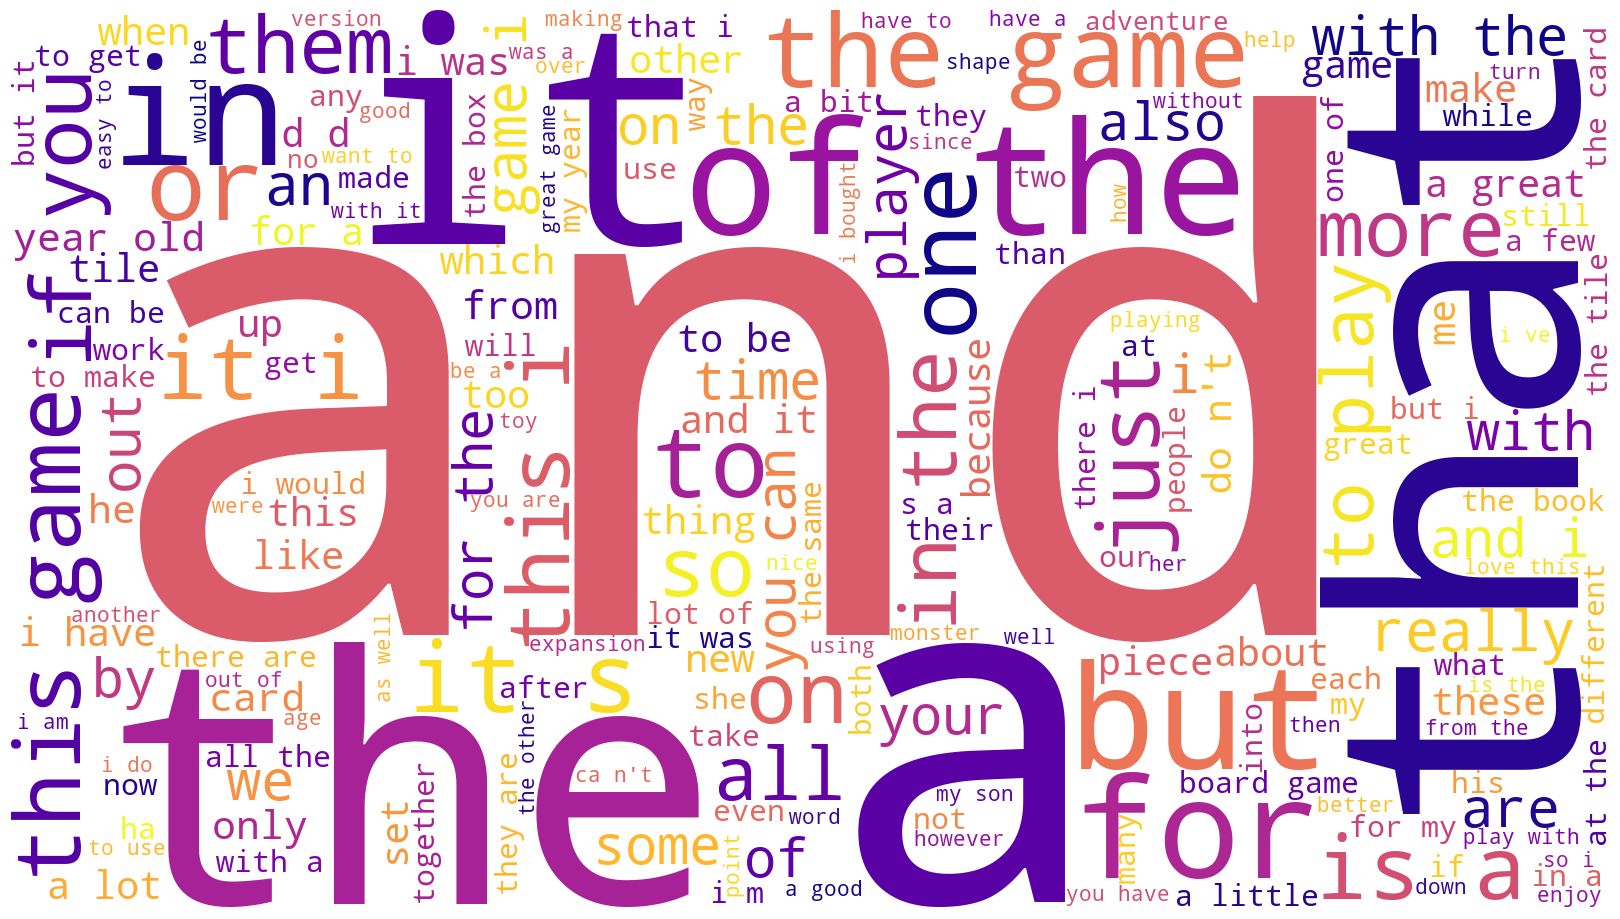

In [72]:
# Review: Plot the WordCloud image.
plt.figure(figsize = (16, 9), facecolor = None)
plt.imshow(review_word_cloud)
plt.axis("off")
plt.tight_layout(pad = 0)
plt.show()

**Observation(s):** Stopwords have not yet been excluded from the review word cloud. Consequently, words such as "and", "the", and "that" dominate the visualisation, obscuring the relative importance of other, more meaningful words.

In [73]:
# Review: Create a word cloud without stopwords.
# Set the colour palette.
sns.set(color_codes=True)

# Create a WordCloud object.
review_word_cloud = WordCloud(width = 1600, height = 900, 
                background_color = "white", 
                colormap = "plasma", 
                stopwords = None, 
                min_font_size = 10).generate(all_reviews_text)

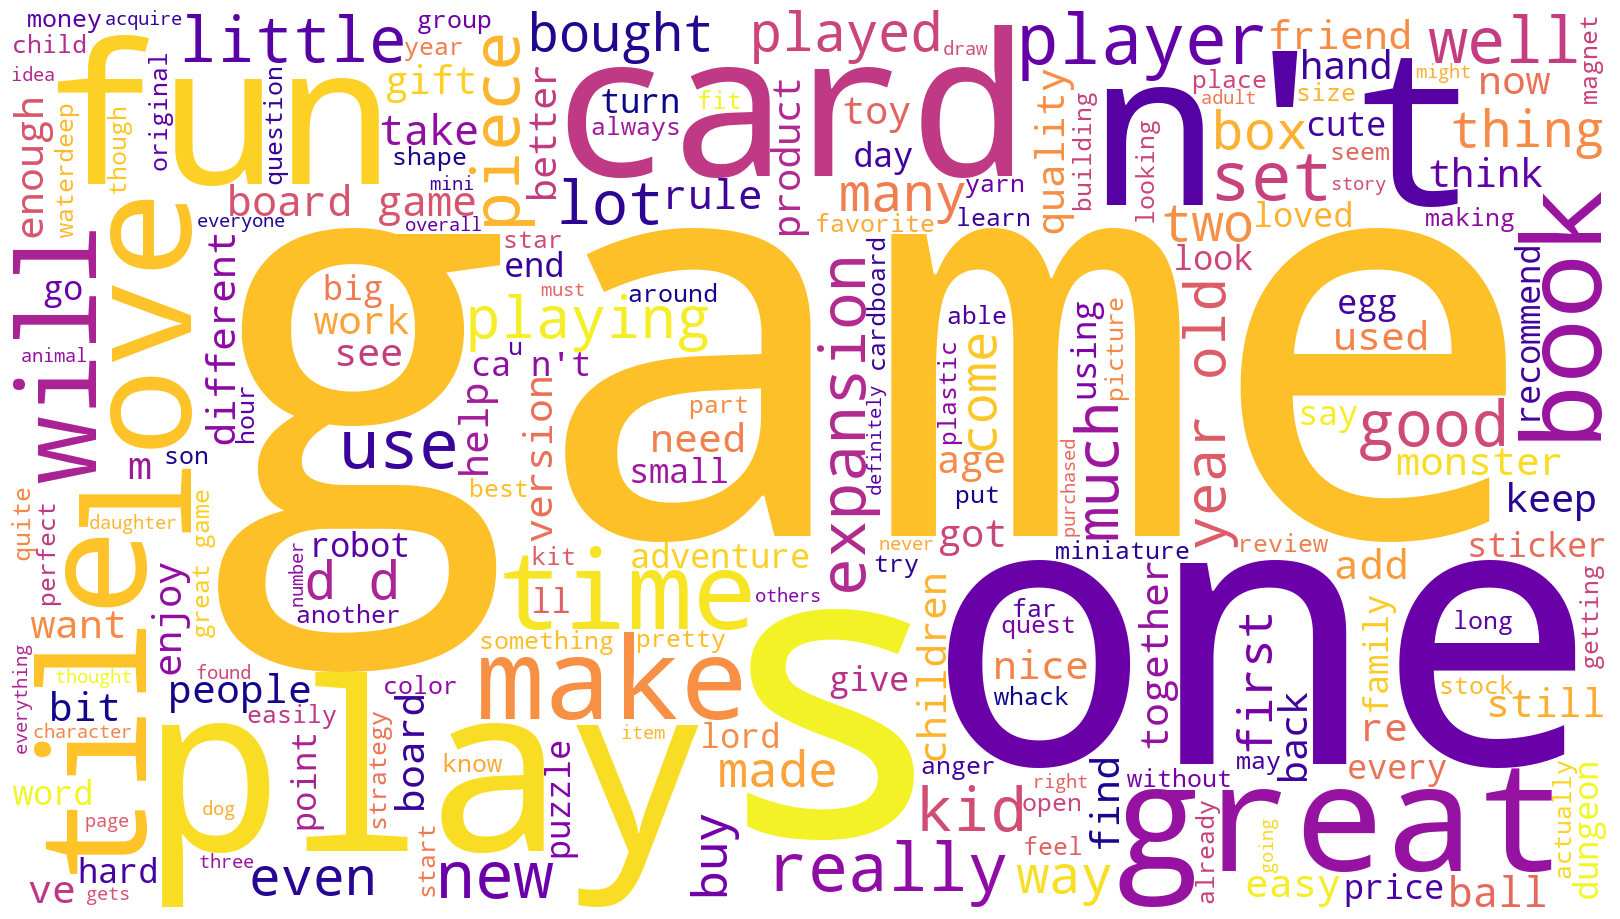

In [74]:
# Review: Plot the WordCloud image.
plt.figure(figsize = (16, 9), facecolor = None)
plt.imshow(review_word_cloud)
plt.axis("off")
plt.tight_layout(pad = 0)
plt.show()

**Observation(s):** Stopwords have now been excluded from the review word cloud. Consequently, words such as "and", "the", and "that" are no longer present, making the relative importance of other, more meaningful words clearer, including "game", "play", and "one".

In [75]:
# Define an empty list of summary tokens.
all_summary_tokens = []

for i in range(survey_tokens.shape[0]):
    # Add each token to the list.
    all_summary_tokens = all_summary_tokens + survey_tokens["summary_tokens"][i]

In [76]:
# Convert all_summary_tokens into one string.
all_summary_text = " ".join(all_summary_tokens)

In [77]:
# Summary: Create a word cloud with stopwords.
# Set the colour palette.
sns.set(color_codes=True)

# Create a WordCloud object.
summary_word_cloud = WordCloud(width = 1600, height = 900, 
                background_color = "white", 
                colormap = "plasma", 
                stopwords = set(), 
                min_font_size = 10).generate(all_summary_text)

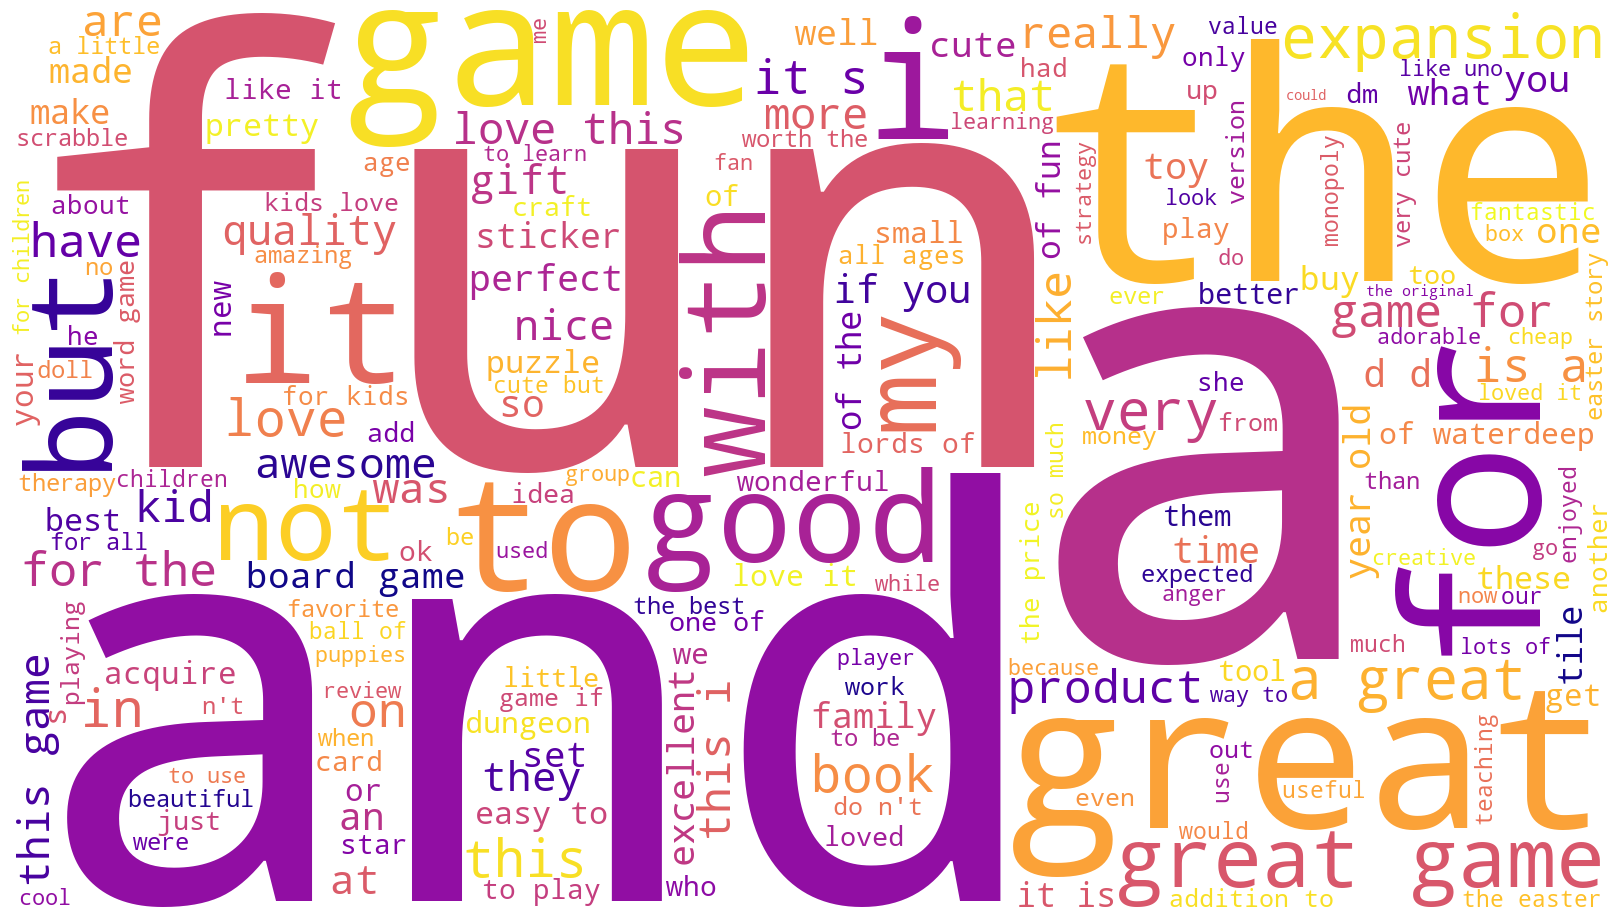

In [78]:
# summary: Plot the WordCloud image.
plt.figure(figsize = (16, 9), facecolor = None)
plt.imshow(summary_word_cloud)
plt.axis("off")
plt.tight_layout(pad = 0)
plt.show()

**Observation(s):** Stopwords have not yet been excluded from the summary word cloud. Consequently, words such as "and", "the", and "with" dominate the visualisation, obscuring the relative importance of other, more meaningful words.

In [79]:
# Summary: Create a word cloud without stopwords.
# Set the colour palette.
sns.set(color_codes=True)

# Create a WordCloud object.
summary_word_cloud = WordCloud(width = 1600, height = 900, 
                background_color = "white", 
                colormap = "plasma", 
                stopwords = None, 
                min_font_size = 10).generate(all_summary_text)

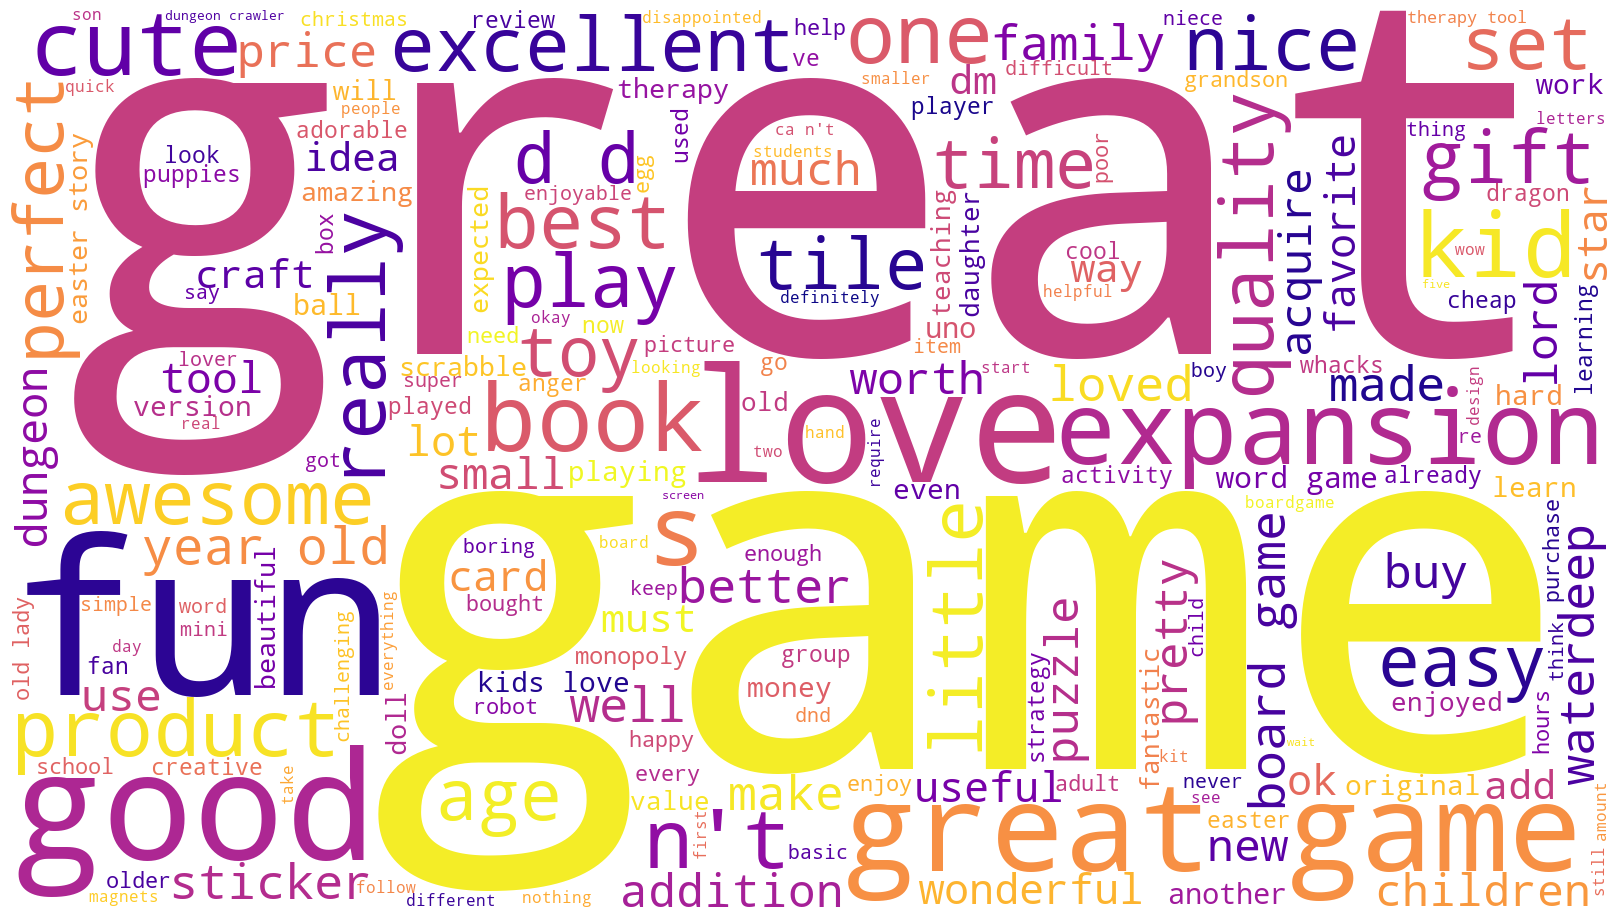

In [80]:
# summary: Plot the WordCloud image.
plt.figure(figsize = (16, 9), facecolor = None)
plt.imshow(summary_word_cloud)
plt.axis("off")
plt.tight_layout(pad = 0)
plt.show()

**Observation(s):** Stopwords have now been excluded from the summary word cloud. Consequently, words such as "and", "the", and "with" are no longer present, making the relative importance of other, more meaningful words clearer, including "great", "game", and "fun".

## 4. Frequency distribution and polarity
### 4a) Create frequency distribution

In [81]:
# Determine the frequency distribution.

# Create a new variable to store all_review_tokens and all_summary_tokens.
all_tokens = all_review_tokens + all_summary_tokens

# Create a new variable to store the frequency distribution of all_tokens.
fdist = FreqDist(all_tokens)

# Preview data.
fdist

FreqDist({'.': 6107, 'the': 5389, ',': 3732, 'and': 3196, 'a': 3162, 'to': 3109, 'of': 2460, 'it': 2435, 'i': 2269, 'is': 1796, ...})

**Observation(s):** Neither punctuation nor stopwords have yet been excluded from the frequency distribution. Consequently, punctuation such as periods and commas, together with common words such as "the", "and", and "to" dominate the results. This obscures the frequencies of other, more meaningful words.

### 4b) Remove alphanumeric characters and stopwords

In [82]:
# Keep only alphanumeric tokens.
tokens = [word for word in all_tokens if word.isalnum()]

In [83]:
# Remove all the stopwords.

# Create a filtered list of tokens without stopwords.
tokens2 = [x for x in tokens if x.lower() not in english_stopwords]

# Define an empty string variable.
tokens2_string = ""

for value in tokens2:
    # Add each filtered token word to the string.
    tokens2_string = tokens2_string + value + " "

### 4c) Create wordcloud without stopwords

In [84]:
# Create a wordcloud without stopwords.
wordcloud = WordCloud(width = 1600, height = 900, 
                background_color = "white", 
                colormap = "plasma", 
                stopwords = None, 
                min_font_size = 10).generate(tokens2_string)

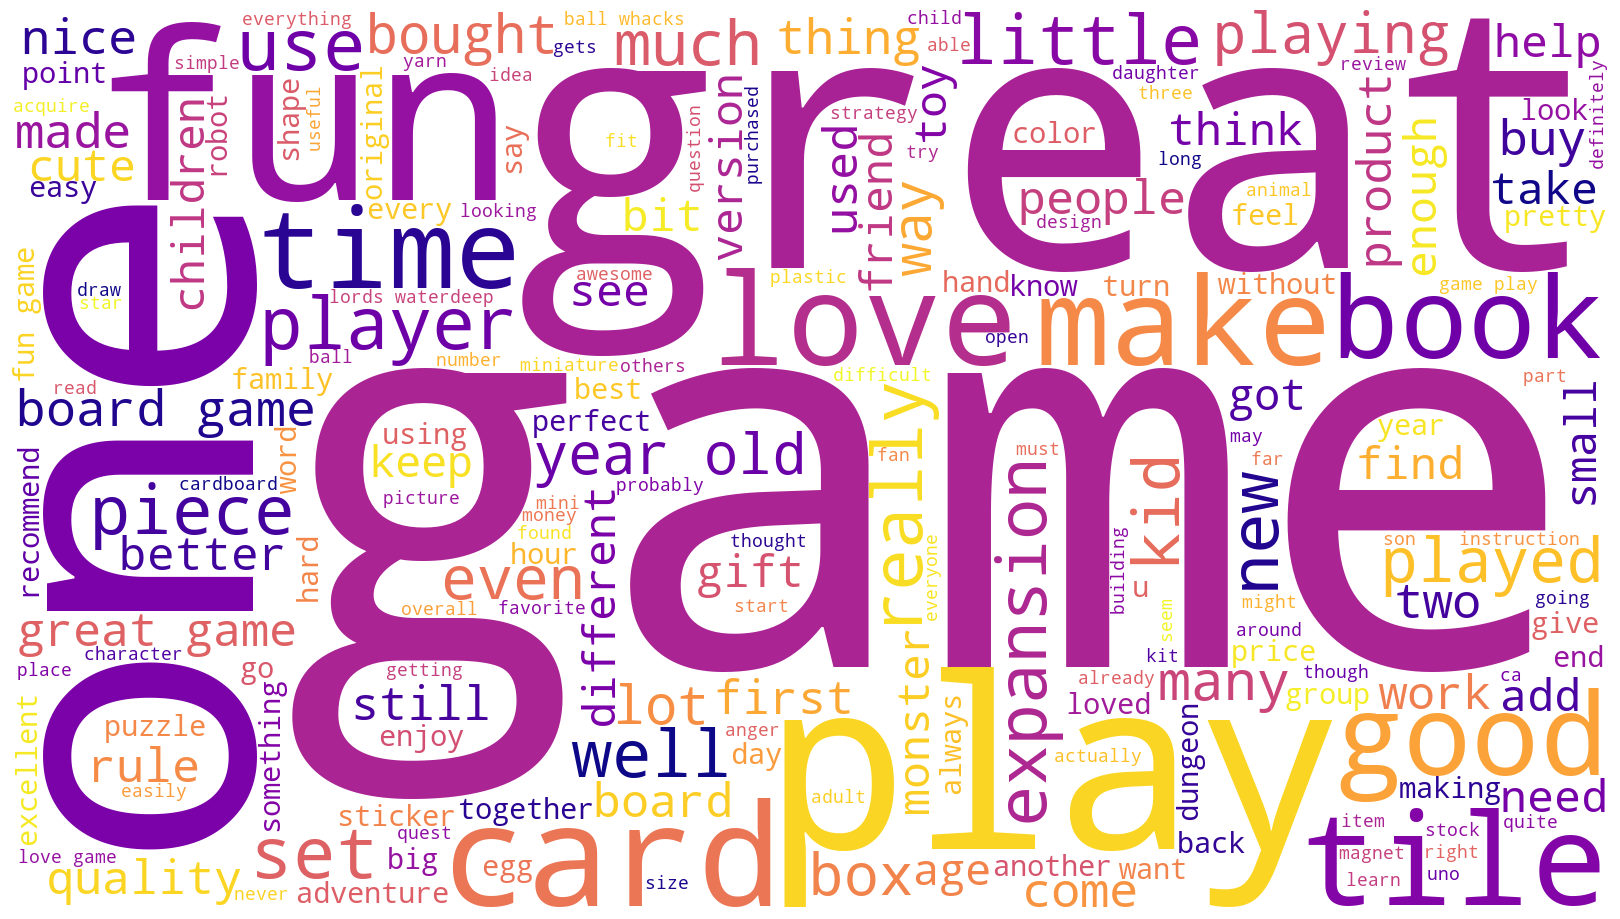

In [85]:
# Plot the WordCloud image.
plt.figure(figsize = (16, 9), facecolor = None)
plt.imshow(wordcloud)
plt.axis("off")
plt.tight_layout(pad = 0)
plt.show()

**Observation(s):** Punctuation and stopwords have now been excluded from the word cloud. Consequently, the relative frequencies of meaningful words such as “game,” “great,” and “one” are much clearer.

### 4d) Identify 15 most common words and polarity

In [86]:
# Determine the 15 most common words.

# View the frequency distribution.
fdist1 = FreqDist(tokens2)

# Preview the data.
fdist1

FreqDist({'game': 1700, 'great': 669, 'fun': 610, 'one': 517, 'play': 481, 'like': 435, 'love': 327, 'good': 324, 'really': 316, 'get': 315, ...})

In [87]:
# Generate a DataFrame from Counter.
counts = pd.DataFrame(Counter(tokens2).most_common(15),
                      columns=["word", "frequency"]).set_index("word")

# Preview data.
counts

,frequency
word,
game,1700
great,669
fun,610
one,517
play,481
like,435
love,327
good,324
really,316


In [88]:
# Define a function to extract a polarity score for the 15 most common words.
def generate_polarity(word):
    return TextBlob(word).sentiment.polarity

# Calculate polarity for each word in the index.
counts["polarity"] = counts.index.to_series().apply(generate_polarity)

# Preview the result.
counts.head()

,frequency,polarity
word,,
game,1700,-0.4
great,669,0.8
fun,610,0.3
one,517,0.0
play,481,0.0


**Observation(s):**

The most frequent word is "game", appearing 1,700 times. Its polarity score is -0.4, indicating a moderately negative sentiment score for the word. This is unexpected given Turtle Games’s role as a game retailer. However, the polarity score applies to the word "game", not to the reviews in which the word appears. Reviews containing this word may, therefore, express positive, negative, or neutral sentiment.

The next most frequent words are "great" and "fun", appearing 669 and 610 times respectively. Their polarity scores of 0.8 and 0.3 indicate positive sentiment, which is consistent with the meanings of these words.

The fourth and fifth most frequent words are "one" and "play", appearing 517 and 481 times respectively. Both have polarity scores of 0.0, indicating neutral sentiment. This is unsurprising because neither word inherently conveys positive or negative sentiment.

## 5. Review the polarity (sentiment) and subjectivity of the review and summary columns, then plot histograms of each (using 15 bins):

In [89]:
# Define a function to extract polarity scores for comments.
def generate_polarity(comment):
    return TextBlob(comment).sentiment.polarity

survey_tokens["review_polarity"] = (survey_tokens["review"].apply(generate_polarity))

survey_tokens["summary_polarity"] = (survey_tokens["summary"].apply(generate_polarity))

print(survey_tokens[["review_polarity", "summary_polarity"]].head())

   review_polarity  summary_polarity
0        -0.036111              0.15
1         0.035952             -0.80
2         0.116640              0.00
3         0.628788              0.00
4        -0.316667              0.00


**Observation(s):** The polarity (sentiment) of each review and each summary is now available.

In [90]:
# Define a function to calculate subjectivity of comments.
def generate_subjectivity(comment):
    return TextBlob(comment).sentiment.subjectivity

survey_tokens["review_subjectivity"] = (survey_tokens["review"].apply(generate_subjectivity))

survey_tokens["summary_subjectivity"] = (survey_tokens["summary"].apply(generate_subjectivity))

print(survey_tokens[["review_subjectivity", "summary_subjectivity"]].head())

   review_subjectivity  summary_subjectivity
0             0.486111              0.500000
1             0.442976              0.900000
2             0.430435              0.733333
3             0.784848              0.000000
4             0.316667              0.000000


**Observation(s):** The subjectivity of each review and each summary is now available, with a value closer to 0 indicating greater objectivity (fact-based) and a value closer to 1 indicating greater subjectivity (opinion-based).

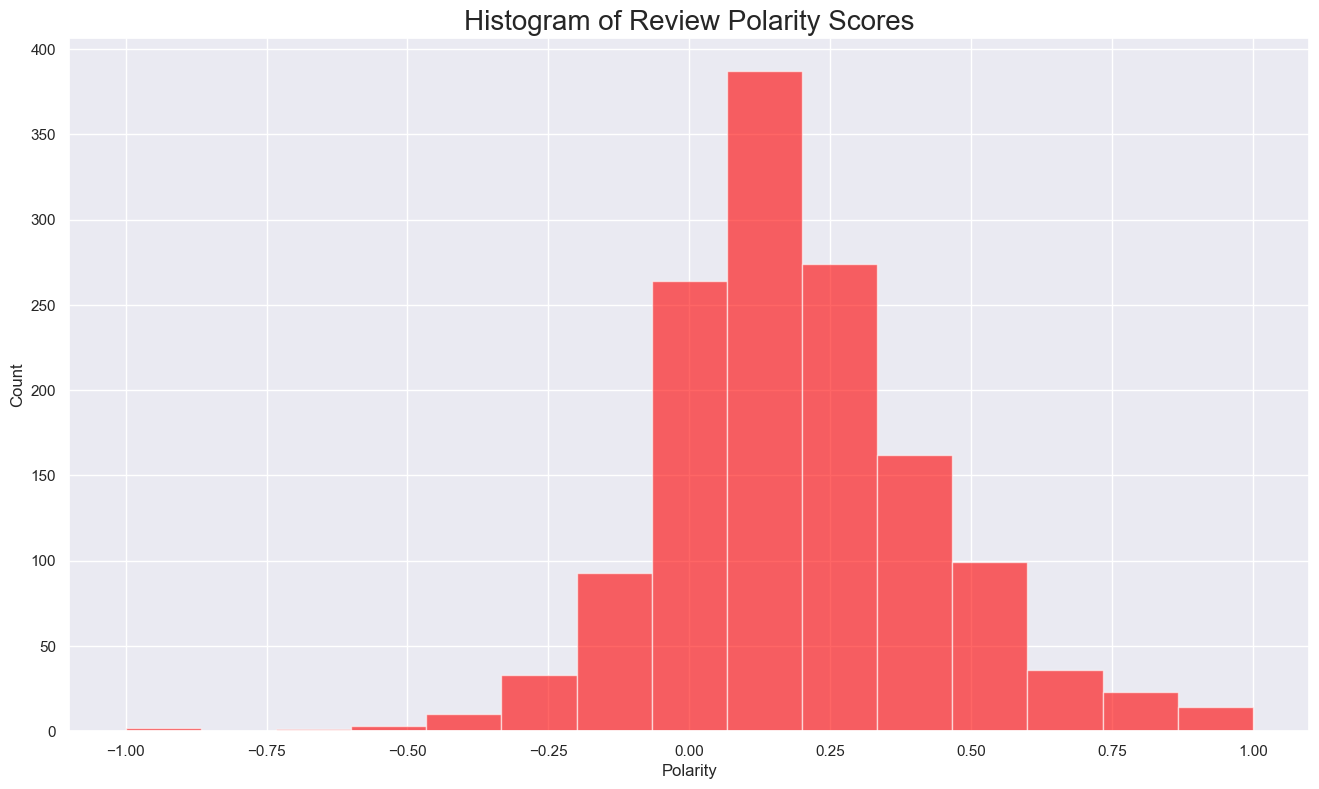

In [91]:
# Review Polarity: Create a histogram plot with bins = 15.
# Set the number of bins.
num_bins = 15

# Set the plot area.
plt.figure(figsize=(16,9))

# Define the bars.
n, bins, patches = plt.hist(survey_tokens["review_polarity"], num_bins, facecolor = "red", alpha = 0.6)

# Set the labels.
plt.xlabel("Polarity", fontsize = 12)
plt.ylabel("Count", fontsize = 12)
plt.title("Histogram of Review Polarity Scores", fontsize = 20)

plt.show()

**Observation(s):** Most review comments are concentrated near neutral or slightly positive polarity values. This indicates that the comments express an overall slightly positive sentiment, rather than strongly positive or strongly negative sentiment.

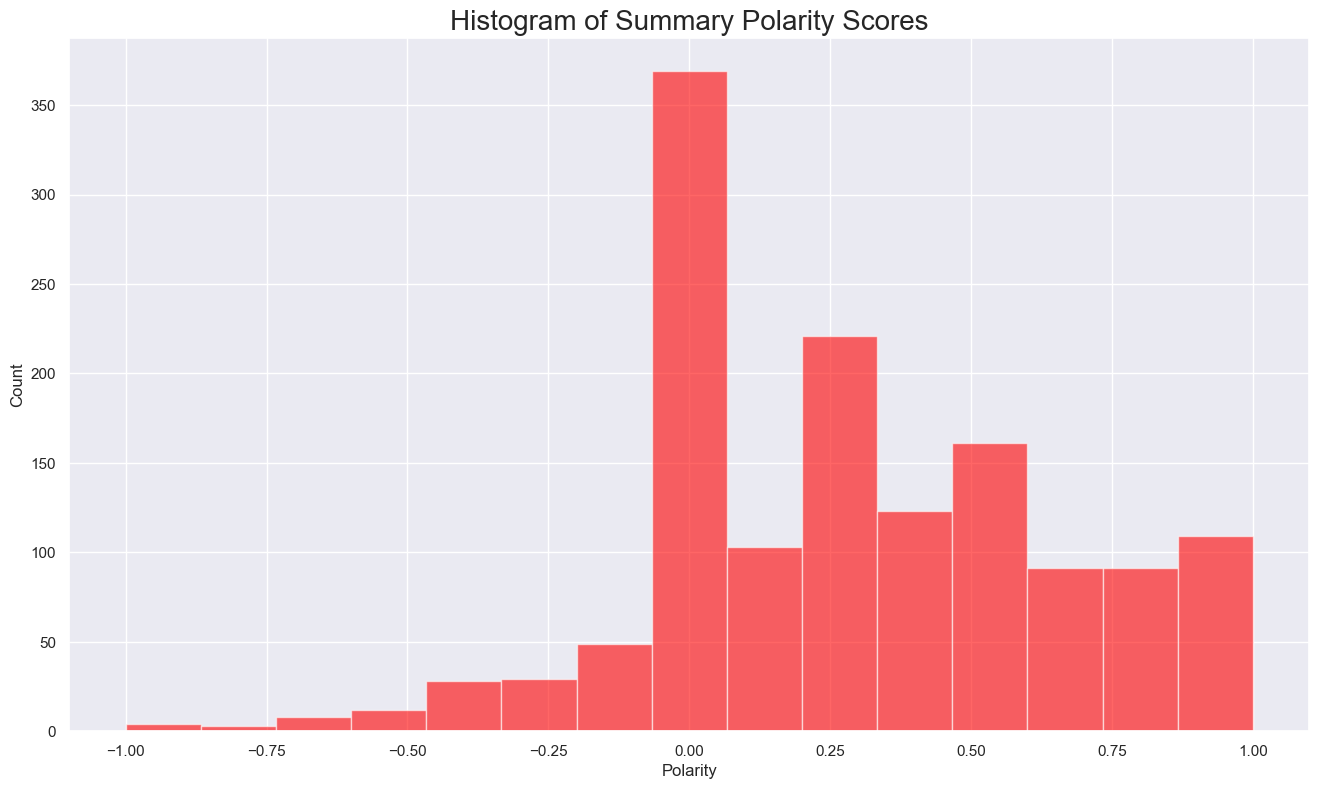

In [92]:
# Summary Polarity: Create a histogram plot with bins = 15.
# Set the number of bins.
num_bins = 15

# Set the plot area.
plt.figure(figsize=(16,9))

# Define the bars.
n, bins, patches = plt.hist(survey_tokens["summary_polarity"], num_bins, facecolor = "red", alpha = 0.6)

# Set the labels.
plt.xlabel("Polarity", fontsize = 12)
plt.ylabel("Count", fontsize = 12)
plt.title("Histogram of Summary Polarity Scores", fontsize = 20)

plt.show()

**Observation(s):** Many summary comments are concentrated near neutral polarity values, indicating that these comments express an overall neutral sentiment, rather than positive or negative sentiment. However, there are also noticeable concentrations of comments near the polarity values of 0.25 and 0.50, both of which are positive, indicating that a large number of reviews are slightly and moderately positive in sentiment.

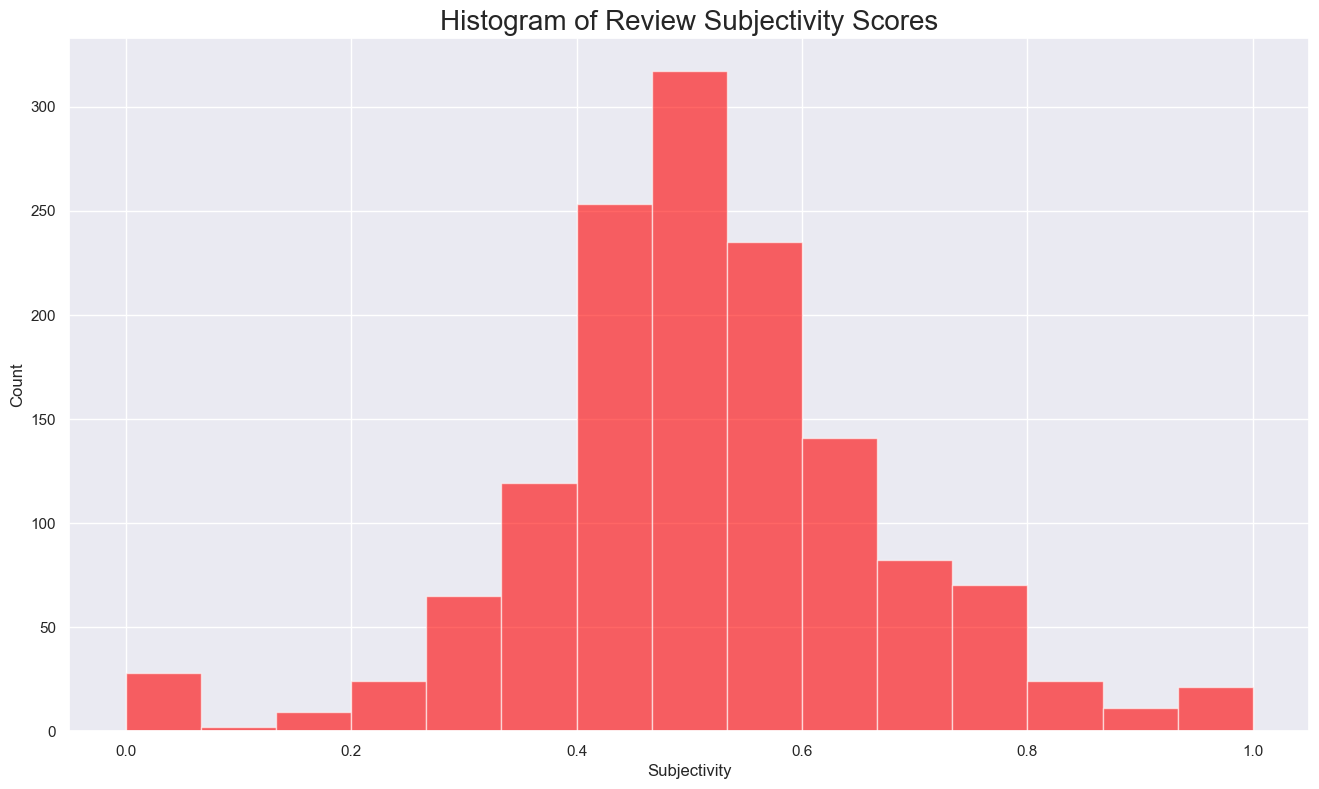

In [93]:
# Review Subjectivity: Create a histogram plot with bins = 15.
# Set the number of bins.
num_bins = 15

# Set the plot area.
plt.figure(figsize=(16,9))

# Define the bars.
n, bins, patches = plt.hist(survey_tokens["review_subjectivity"], num_bins, facecolor = "red", alpha = 0.6)

# Set the labels.
plt.xlabel("Subjectivity", fontsize = 12)
plt.ylabel("Count", fontsize = 12)
plt.title("Histogram of Review Subjectivity Scores", fontsize = 20)

plt.show()

**Observation(s):** Most review comments have subjectivity scores between 0.4 and 0.6. This suggests that the reviews contain a moderate mixture of fact-based language and opinion-based language, rather than being strongly objective or strongly subjective.

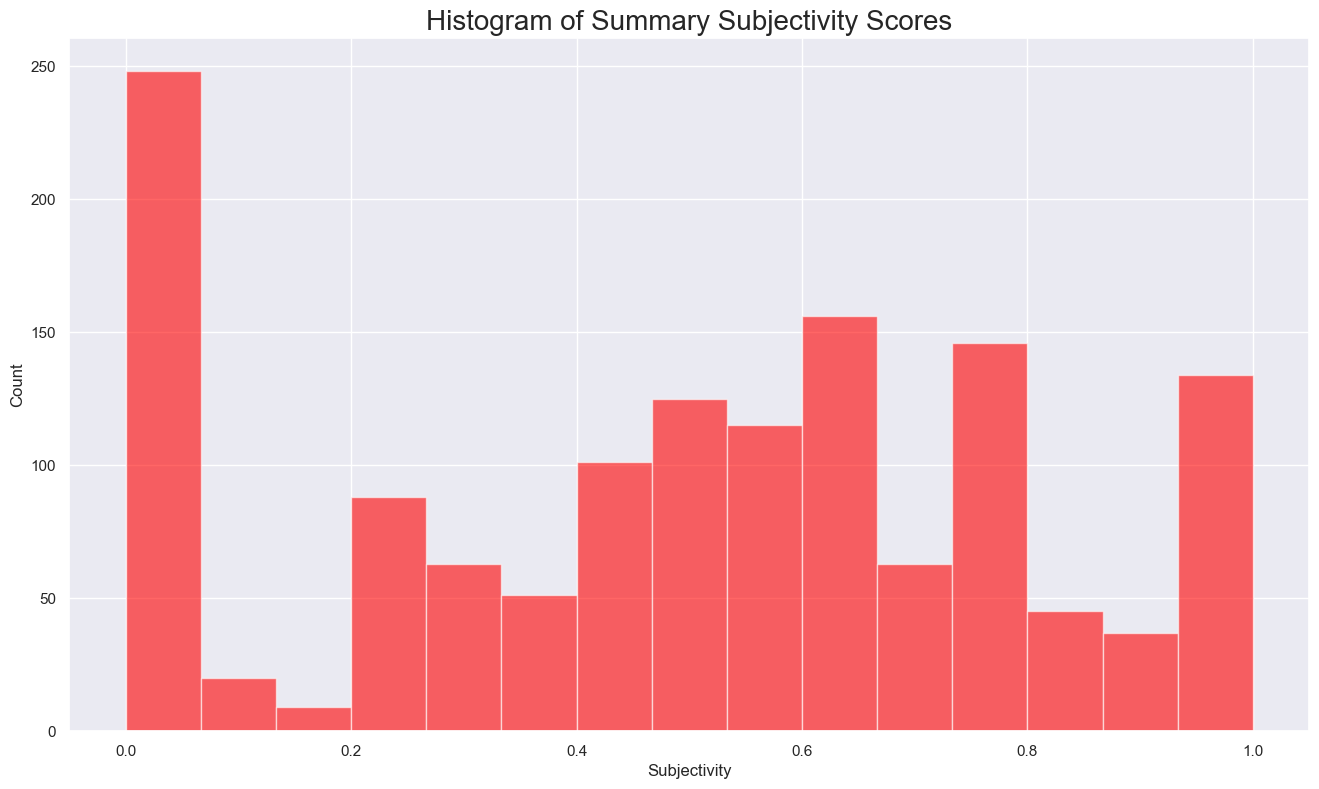

In [94]:
# Summary Subjectivity: Create a histogram plot with bins = 15.
# Set the number of bins.
num_bins = 15

# Set the plot area.
plt.figure(figsize=(16,9))

# Define the bars.
n, bins, patches = plt.hist(survey_tokens["summary_subjectivity"], num_bins, facecolor = "red", alpha = 0.6)

# Set the labels.
plt.xlabel("Subjectivity", fontsize = 12)
plt.ylabel("Count", fontsize = 12)
plt.title("Histogram of Summary Subjectivity Scores", fontsize = 20)

plt.show()

**Observation(s):** Many summary comments have subjectivity scores near 0.0, suggesting that these summaries mostly contain objective, fact-based language. However, there are also noticeable concentrations of comments near the subjectivity scores of 0.6, 0.8, and 1.0. These scores indicate that many of the summaries mostly contain subjective, opinion-based language.

## 6. Identify top 20 positive and negative reviews and summaries respectively

In [95]:
# Top 20 negative reviews.

# Create a DataFrame containing the 20 lowest polarity scores.
review_negative_sentiment = survey_tokens.nsmallest(20, "review_polarity")

# Eliminate unnecessary columns.
review_negative_sentiment = review_negative_sentiment[["review", "review_polarity"]]

# Adjust the review column width.
review_negative_sentiment.style.set_properties(subset = ["review"], **{"width": "1200px"})

,review,review_polarity
166,booo unles you are patient know how to measure i didn't have the patience neither did my daughter. boring unless you are a craft person which i am not.,-1.000000
147,incomplete kit! very disappointing!,-0.975000
735,"if you, like me, used to play d&d, but now you and your friends ""growed up"" and can't be together because all the responsibilities and bla bla bla... this game is for you! come to the dungeon!",-0.625000
270,"one of my staff will be using this game soon, so i don't know how well it works as yet, but after looking at the cards, i believe it will be helpful in getting a conversation started regarding anger and what to do to control it.",-0.550000
90,i bought this as a christmas gift for my grandson. its a sticker book. so how can i go wrong with this gift.,-0.500000
141,"i sent this product to my granddaughter. the pom-pom maker comes in two parts and is supposed to snap together to create the pom-poms. however, both parts were the same making it unusable. if you can't make the pom-poms the kit is useless. since this was sent as a gift, i do not have it to return. very disappointed.",-0.491667
253,my 8 year-old granddaughter and i were very frustrated and discouraged attempting this craft. it is definitely not for a young child. i too had difficulty understanding the directions. we were very disappointed!,-0.452500
388,i purchased this on the recommendation of two therapists working with my adopted children. the children found it boring and put it down half way through.,-0.440741
316,this game although it appears to be like uno and have an easier play method it was still too time consuming and wordy for my children with learning disabilities.,-0.400000
360,my son loves playing this game. it was recommended by a counselor at school that works with him.,-0.400000


**Observation(s):** Review no. 735 and 270 appear to be positive in sentiment, despite them having the third and fourth lowest polarity scores respectively. Review no. 360, 1042, 336, 301, and 397 also appear to have been incorrectly classified as negative in sentiment. Therefore, 7/20 of the reviews with the lowest polarity scores (approximately 35%) appear to have been misclassified. This raises concerns about the accuracy and usefulness of using polarity scores alone to classify the sentiment of the reviews.

In [96]:
# Top 20 negative summaries.

# Create a DataFrame containing the 20 lowest polarity scores.
summary_negative_sentiment = survey_tokens.nsmallest(20, "summary_polarity")

# Eliminate unnecessary columns.
summary_negative_sentiment = summary_negative_sentiment[["summary", "summary_polarity"]]

# Adjust the review column width.
summary_negative_sentiment.style.set_properties(subset = ["summary"], **{"width": "1200px"})

,summary,summary_polarity
17,the worst value i've ever seen,-1.000000
166,boring unless you are a craft person which i am ...,-1.000000
602,boring,-1.000000
862,before this i hated running any rpg campaign dealing with towns because it ...,-0.900000
1,another worthless dungeon master's screen from galeforce9,-0.800000
116,disappointed,-0.750000
458,disappointed.,-0.750000
269,promotes anger instead of teaching calming methods,-0.700000
651,"too bad, this is not what i was expecting.",-0.700000
656,bad quality-all made of paper,-0.700000


**Observation(s):** Summary no. 602 appears to be positive in sentiment, despite it having the third lowest polarity score. Summary no. 373 and 1295 appear to be neutral in sentiment, meaning they may also have been incorrectly classified as negative in sentiment. However, 17/20 of the reviews with the lowest polarity scores (approximately 85%) appear to have been correctly classified. These results are much more encouraging than the results of the review polarity scores, but they should still be interpreted alongside a manual review of the original comments, to determine accuracy.

In [97]:
# Top 20 positive reviews.

# Create a DataFrame containing the 20 highest polarity scores.
review_positive_sentiment = survey_tokens.nlargest(20, "review_polarity")

# Eliminate unnecessary columns.
review_positive_sentiment = review_positive_sentiment[["review", "review_polarity"]]

# Adjust the review column width.
review_positive_sentiment.style.set_properties(subset = ["review"], **{"width": "1200px"})

,review,review_polarity
341,great seller!!! happy with my purchase!!! 5 starrrr,1.000000
449,great easter gift for kids!,1.000000
504,these are great!,1.000000
578,perfect!,1.000000
589,great!!,1.000000
851,great accessory to use with the playing mat!,1.000000
1149,great doll to go with the book & animals! can't wait to read book with the doll to the grandkids!,1.000000
1223,"great education ""toy""!",1.000000
1386,perfect for tutoring my grandson in spelling.,1.000000
915,"the best part i see is the box! what a wonderfully diverse and rounded set for the cost. i am so happy, and, as the dm, you know that if i am happy, my players are happy!",0.920000


**Observation(s):** All of the top 20 positive reviews appear to have been correctly classified.

In [98]:
# Top 20 positive summaries.

# Create a DataFrame containing the 20 highest polarity scores.
summary_positive_sentiment = survey_tokens.nlargest(20, "summary_polarity")

# Eliminate unnecessary columns.
summary_positive_sentiment = summary_positive_sentiment[["summary", "summary_polarity"]]

# Adjust the review column width.
summary_positive_sentiment.style.set_properties(subset = ["summary"], **{"width": "1200px"})

,summary,summary_polarity
5,best gm screen ever,1.000000
23,wonderful designs.,1.000000
27,perfect!,1.000000
32,great buy! can't wait to work on this book,1.000000
35,so beautiful!,1.000000
43,great!,1.000000
61,they're the perfect size to keep in the car or a diaper ...,1.000000
95,great for a gift!,1.000000
107,perfect for preschooler,1.000000
112,awesome sticker activity for the price,1.000000


**Observation(s):** All of the top 20 positive summaries appear to have been correctly classified.

## 7. Discuss: Insights and observations

***Your observations here...***

This analysis indicates that customers generally express positive sentiment towards Turtle Games's products. The most common words identified were "game", "great", "fun", "one", and "play", suggesting that customers primarily discuss enjoyment, gameplay, and product experiences. Whilst several of the most frequent words had positive sentiment scores, it is important to note that word-level sentiment does not necessarily reflect the sentiment of the reviews in which those words appear.

The polarity analysis showed that most reviews and summaries were neutral to slightly positive in sentiment, whilst the subjectivity analysis indicated that reviews typically contain a mixture of factual information and personal opinions. This suggests that customer reviews may provide valuable insights into product performance and customer perceptions.

However, manual inspection of the most positive and negative reviews identified several instances of sentiment misclassification. This suggests that polarity scores alone should not be relied upon when making decisions and should instead be used alongside manual review or more advanced NLP techniques.

Turtle Games should consider collecting additional text-based feedback and exploring more sophisticated sentiment-analysis methods to improve the accuracy and usefulness of future customer insight activities. Manual reviews should also be undertaken to help assess the accuracy of the NLP techniques employed.